# Analisis Big Data NYC Yellow Taxi (Desember 2025) dengan PySpark

**Nama:** Muhammad Rifky Alfajri · **NIM:** 103012430036 · **Kelas:** BS1 IF 48 GAB01
**Mata kuliah:** Big Data and Artificial Intelligence, Midterm Project · S1 Informatika, Telkom University

**Alur notebook:** (1) rumusan masalah dan 5V → (2) sumber data, penyimpanan, arsitektur → (3) setup dan ingestion → (4) profiling → (5) cleaning dan quality checks → (6) analisis PySpark dan Spark SQL → (7) pemodelan → (8) visualisasi → (9) temuan, keterbatasan, rekomendasi.

## 1. Rumusan masalah dan pemahaman Big Data

**Pertanyaan utama.** Bagaimana struktur tarif, perilaku tip, dan pola perjalanan jauh NYC Yellow Taxi pada Desember 2025, dan seberapa jauh tarif argo standar dapat diprediksi dibanding baseline sederhana?

| No | Pertanyaan turunan | Ukuran jawaban |
|---|---|---|
| Q1 | Pada kombinasi hari dan jam mana **median** persentase tip pembayaran kartu kredit paling tinggi, dan apakah 5 teratas berbeda secara statistik? | Median dan rata-rata tip%, jumlah trip, interval kepercayaan 95% (minimal 500 trip per slot) |
| Q2 | Ke mana tujuan perjalanan jauh (> 10 mil) pukul 14:00-16:59, dan apakah jam itu memang puncak perjalanan jauh? | Zona tujuan, share (%), volume per jam; dengan dan tanpa filter RatecodeID |
| Q3 | Seberapa akurat Random Forest memprediksi `fare_amount` dibanding baseline rata-rata dan regresi linear, dan fitur mana yang paling berkontribusi? | RMSE, MAE, R², RMSE relatif; drop-column importance |
| Q4 | Berapa besar anomali data, bagaimana pola null `passenger_count`, dan berapa retensi data setelah cleaning? | Tabel waterfall per tahap, pola null per VendorID |
| Q5 | Apakah kolom `extra` dan `cbd_congestion_fee` konsisten dengan aturan tarif resmi TLC? | Distribusi nilai dibanding aturan TLC |

**Pengguna dan keputusan yang dibantu**

- **Pengemudi/pengelola armada:** kapan dan ke mana mengarahkan armada untuk tip dan perjalanan jauh (Q1, Q2).
- **Perencana kebijakan (TLC/MTA):** apakah komponen biaya baru, termasuk congestion pricing, tercatat konsisten (Q5).
- **Pengembang aplikasi tarif/ETA:** apakah tarif dapat diperkirakan sebelum perjalanan dimulai (Q3).

**Ruang lingkup model tarif.** Model hanya untuk tarif argo standar (`RatecodeID = 1`). Tarif tetap JFK (`RatecodeID = 2`, mis. $70) tidak dihitung dari jarak dan durasi sehingga tidak cocok dimodelkan dengan fitur yang sama. Ini keputusan ruang lingkup berbasis aturan tarif TLC, bukan upaya menurunkan error. Dampaknya diukur eksplisit di bagian 7.

**Penilaian 5V berbasis bukti** (angka dilengkapi otomatis oleh sel di bawah)

- **Volume:** jutaan baris dan 20 kolom untuk satu bulan; ukuran file dicetak di bawah.
- **Variety:** terbatas. Data tabular terstruktur (numerik, timestamp, kode kategorikal), tanpa teks bebas atau data semi-terstruktur.
- **Velocity:** rendah. Data dirilis TLC sebagai file bulanan (batch), bukan aliran. Ukuran data besar tidak berarti velocity tinggi.
- **Veracity:** menengah. Ada null sistematis, nilai tidak valid, dan timestamp di luar periode (dibuktikan di bagian 4-5).
- **Value:** tinggi untuk analisis tip, mobilitas, dan evaluasi kebijakan tarif.

## 2. Sumber data, penyimpanan, dan arsitektur

**Provenance**

- **Sumber**: NYC Taxi & Limousine Commission (TLC) Trip Record Data, https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
- **File**: `yellow_tripdata_2025-12.parquet`; lookup zona: `taxi_zone_lookup.csv` (halaman yang sama).

- **Lisensi/Ketentuan (Terms of Use):** 
Data terbuka NYC (NYC Open Data). Data ini merupakan data publik yang disediakan oleh Pemerintah Kota New York secara gratis untuk diunduh dan digunakan oleh siapa saja. Sesuai dengan Ketentuan Penggunaan portal web NYC Open Data: *"Public data sets made available on the web portal are provided for informational purposes. The City does not warranty the completeness, accuracy, content, or fitness for any particular purpose..."*

- **Tanggal Akses:** 1 November 2026
- **Rujukan aturan tarif:** https://www.nyc.gov/site/tlc/passengers/taxi-fare.page dan Data Dictionary Yellow Trip Records.

- **Pipeline**

```
TLC (Parquet bulanan) → Ingestion (spark.read.parquet) → Storage (Parquet: zona raw dan zona clean)
                      → Processing (PySpark DataFrame API + Spark SQL + MLlib) → Output (tabel, grafik, model, laporan)
```

**Pilihan penyimpanan**

| Pertimbangan | SQL (RDBMS) | NoSQL | Data warehouse | Data lake (Parquet) |
|---|---|---|---|---|
| Struktur data | Cocok (skema tetap) | Tidak perlu fleksibilitas skema | Cocok | Cocok |
| Pola akses | Transaksional | Key/document lookup | Agregasi analitik | Agregasi analitik, scan kolom |
| Biaya/kompleksitas | Perlu proses load | Tidak relevan | Perlu ETL dan lisensi/server | Rendah, file langsung dibaca Spark |

**Keputusan:** Parquet di penyimpanan file (gaya data lake) dengan dua zona, raw dan clean. Alasannya: skema tabular tetap, beban kerja baca-berat berupa agregasi, Parquet kolumnar efisien untuk scan beberapa kolom, dan tidak perlu biaya ETL. NoSQL dan streaming tidak diimplementasikan karena tidak ada kebutuhan akses per-key atau aliran data.

**Data dictionary ringkas**

| Kolom | Arti |
|---|---|
| VendorID | Penyedia teknologi taksi |
| tpep_pickup_datetime, tpep_dropoff_datetime | Waktu jemput dan antar |
| passenger_count | Jumlah penumpang (diisi pengemudi) |
| trip_distance | Jarak argometer (mil) |
| RatecodeID | Jenis tarif: 1 standar, 2 JFK (tarif tetap), 3 Newark, 4 Nassau/Westchester, 5 negosiasi, 6 group ride |
| store_and_fwd_flag | Y jika rekaman tersimpan di kendaraan sebelum dikirim |
| PULocationID, DOLocationID | Zona jemput dan antar (1-263) |
| payment_type | 1 kartu kredit, 2 tunai, dst. Tip hanya tercatat otomatis untuk kartu kredit |
| fare_amount | Tarif argo (jarak + waktu) |
| extra | Surcharge malam dan jam sibuk |
| mta_tax, improvement_surcharge | Pajak/surcharge tetap |
| tip_amount, tolls_amount | Tip dan tol |
| congestion_surcharge | Surcharge kemacetan negara bagian (Manhattan selatan Jl. 96) |
| Airport_fee | Biaya bandara |
| cbd_congestion_fee | MTA Congestion Pricing toll (zona selatan Jl. 60) |
| total_amount | Total yang dibayar penumpang |

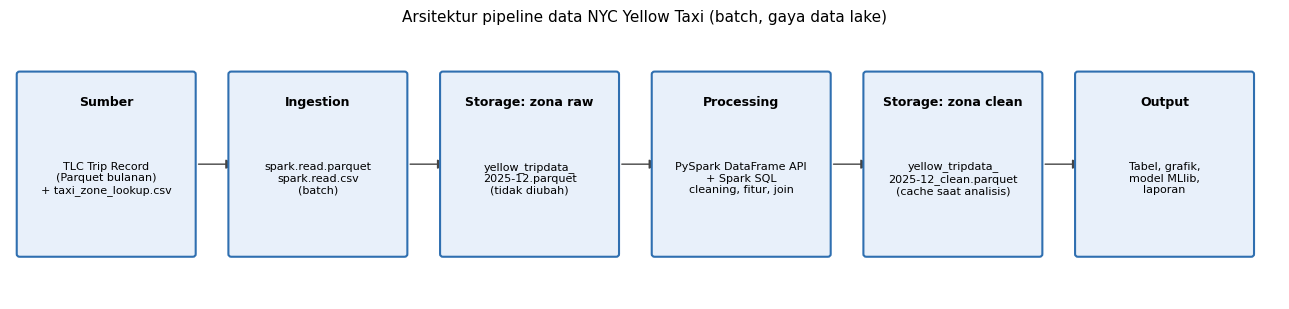

Sumber: rancangan pipeline di bagian 2; diagram digambar dengan matplotlib, tanpa data.


In [1]:
# Diagram alur data: sumber -> ingestion -> storage -> processing -> output
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

stages = [
    ("Sumber", "TLC Trip Record\n(Parquet bulanan)\n+ taxi_zone_lookup.csv"),
    ("Ingestion", "spark.read.parquet\nspark.read.csv\n(batch)"),
    ("Storage: zona raw", "yellow_tripdata_\n2025-12.parquet\n(tidak diubah)"),
    ("Processing", "PySpark DataFrame API\n+ Spark SQL\ncleaning, fitur, join"),
    ("Storage: zona clean", "yellow_tripdata_\n2025-12_clean.parquet\n(cache saat analisis)"),
    ("Output", "Tabel, grafik,\nmodel MLlib,\nlaporan"),
]
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.set_xlim(0, len(stages) * 2.2); ax.set_ylim(0, 3); ax.axis("off")
for i, (title, body) in enumerate(stages):
    x = i * 2.2 + 0.1
    ax.add_patch(FancyBboxPatch((x, 0.5), 1.8, 2.0, boxstyle="round,pad=0.03", fc="#e8f0fa", ec="#2f6fb0", lw=1.5))
    ax.text(x + 0.9, 2.2, title, ha="center", va="center", fontsize=9, fontweight="bold")
    ax.text(x + 0.9, 1.35, body, ha="center", va="center", fontsize=8)
    if i < len(stages) - 1:
        ax.add_patch(FancyArrowPatch((x + 1.83, 1.5), (x + 2.27, 1.5), arrowstyle="-|>", mutation_scale=14, color="#444"))
ax.set_title("Arsitektur pipeline data NYC Yellow Taxi (batch, gaya data lake)", fontsize=11)
plt.tight_layout(); plt.show()
print("Sumber: rancangan pipeline di bagian 2; diagram digambar dengan matplotlib, tanpa data.")

## 3. Setup, konfigurasi, dan ingestion

In [2]:
import os, sys, time, platform
import pyspark
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.stat import Correlation
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Nama: Muhammad Rifky Alfajri \nNIM: 103012430036 \nBS1 IF 48 GAB01")

Nama: Muhammad Rifky Alfajri 
NIM: 103012430036 
BS1 IF 48 GAB01


In [3]:
# ---------- Konfigurasi (ubah di sini saja) ----------
RAW_PATH   = "yellow_tripdata_2025-12.parquet"
ZONE_PATH  = "taxi_zone_lookup.csv"            # opsional tapi disarankan (nama zona)
CLEAN_PATH = "yellow_tripdata_2025-12_clean.parquet"
SEED = 42
ACCESS_DATE = "1 November 2026"               # tanggal data diunduh
MIN_TRIPS_SLOT = 500                           # minimum trip per slot hari-jam untuk Q1
ML_FRACTION = 0.5                              # fraksi data untuk ML; naikkan ke 1.0 jika memori cukup, laporkan nilai yang dipakai
IMP_FRACTION = 0.3                             # fraksi data train untuk drop-column importance
DRIVER_MEMORY = "4g"
SHUFFLE_PARTITIONS = 8

spark = (SparkSession.builder
         .appName("NYC_Taxi_BigData_Analysis")
         .config("spark.driver.memory", DRIVER_MEMORY)
         .config("spark.sql.shuffle.partitions", str(SHUFFLE_PARTITIONS))
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")

print("=== LINGKUNGAN ===")
print("Python         :", sys.version.split()[0])
print("PySpark        :", pyspark.__version__, "| Spark runtime:", spark.version)
print("OS / CPU       :", platform.platform(), "/", os.cpu_count(), "core")
print("Driver memory  :", DRIVER_MEMORY, "| shuffle partitions:", SHUFFLE_PARTITIONS)
print("Seed           :", SEED, "| tanggal akses data:", ACCESS_DATE)

# Pencatat waktu: dipakai konsisten untuk semua pengukuran
TIMINGS = []
def timed(label, fn, repeats=3):
    runs = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); runs.append(time.perf_counter() - t0)
    TIMINGS.append({"operasi": label, "run_1_s": round(runs[0], 2),
                    "min_s": round(min(runs), 2), "median_s": round(sorted(runs)[len(runs)//2], 2)})
    return runs

=== LINGKUNGAN ===
Python         : 3.13.1
PySpark        : 4.2.0 | Spark runtime: 4.2.0
OS / CPU       : Windows-11-10.0.26340-SP0 / 16 core
Driver memory  : 4g | shuffle partitions: 8
Seed           : 42 | tanggal akses data: 1 November 2026


In [4]:
df_raw = spark.read.parquet(RAW_PATH)
n_raw = df_raw.count()
raw_cols = df_raw.columns
size_mb = (sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(RAW_PATH) for f in fs)
           if os.path.isdir(RAW_PATH) else os.path.getsize(RAW_PATH)) / 1e6

print("=== DOKUMENTASI AWAL DATASET ===")
print(f"Jumlah record : {n_raw:,}")
print(f"Jumlah kolom  : {len(raw_cols)}")
print(f"Jumlah partisi: {df_raw.rdd.getNumPartitions()}")
print(f"Ukuran file   : {size_mb:,.1f} MB (Parquet terkompresi)")
print("\n=== SKEMA ===")
df_raw.printSchema()
df_raw.limit(5).show(truncate=False)   # data taksi tidak memuat identitas pribadi

=== DOKUMENTASI AWAL DATASET ===
Jumlah record : 4,305,006
Jumlah kolom  : 20
Jumlah partisi: 16
Ukuran file   : 73.7 MB (Parquet terkompresi)

=== SKEMA ===
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airpor

In [5]:
# Lookup nama zona (join relevan untuk Q2). Jika file tidak ada, notebook tetap jalan dengan label "Zone <id>".
if os.path.exists(ZONE_PATH):
    zones = (spark.read.csv(ZONE_PATH, header=True, inferSchema=True)
             .select(F.col("LocationID").cast("int").alias("LocationID"), "Borough", "Zone"))
    print("Lookup zona dimuat:", zones.count(), "zona")
else:
    zones = spark.range(1, 264).select(F.col("id").cast("int").alias("LocationID"),
                                       F.lit(None).cast("string").alias("Borough"),
                                       F.concat(F.lit("Zone "), F.col("id").cast("string")).alias("Zone"))
    print("PERINGATAN: taxi_zone_lookup.csv tidak ditemukan; nama zona diganti 'Zone <id>'. Unduh dari halaman TLC untuk hasil lengkap.")
zones.createOrReplaceTempView("zones")

Lookup zona dimuat: 265 zona


## 4. Profiling data mentah (EDA awal)

In [6]:
# Kolom turunan awal yang diperlukan untuk profiling dan aturan validasi
df0 = df_raw.withColumn("trip_duration_min",
        (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60.0)

# 4.1 Statistik deskriptif kolom numerik
num_cols = [c for c, t in df_raw.dtypes if t in ("int", "bigint", "double")]
print("=== STATISTIK DESKRIPTIF (data mentah) ===")
print(df_raw.select(num_cols).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
      .toPandas().set_index("summary").T.to_string())

# 4.2 Missing values per kolom
null_counts = df_raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in raw_cols]).first().asDict()
null_pdf = pd.DataFrame({"kolom": list(null_counts), "null": list(null_counts.values())})
null_pdf["persen"] = (null_pdf["null"] / n_raw * 100).round(2)
print("\n=== MISSING VALUES ===")
print(null_pdf[null_pdf["null"] > 0].to_string(index=False))

# 4.3 Duplikasi baris penuh
n_dedup_raw = df_raw.dropDuplicates().count()
print(f"\n=== DUPLIKASI ===\nBaris duplikat penuh: {n_raw - n_dedup_raw:,}")

# 4.4 Rentang tanggal (file Desember sering memuat timestamp nyasar)
rng = df_raw.agg(F.min("tpep_pickup_datetime").alias("min_pickup"), F.max("tpep_pickup_datetime").alias("max_pickup")).first()
n_out_period = df_raw.filter(~((F.year("tpep_pickup_datetime") == 2025) & (F.month("tpep_pickup_datetime") == 12))).count()
print(f"\n=== RENTANG WAKTU ===\nPickup: {rng['min_pickup']} s/d {rng['max_pickup']}")
print(f"Baris dengan pickup di luar Desember 2025 (atau null): {n_out_period:,}")

# 4.5 Persentil untuk menjustifikasi ambang outlier
q = df0.approxQuantile(["trip_distance", "fare_amount", "trip_duration_min"], [0.5, 0.99, 0.999], 0.0001)
print("\n=== PERSENTIL (median, p99, p99.9) ===")
for name, vals in zip(["trip_distance", "fare_amount", "trip_duration_min"], q):
    print(f"{name:18s}: {vals}")

# 4.6 Distribusi kolom kategorikal
for c in ["RatecodeID", "payment_type", "VendorID"]:
    print(f"\n=== DISTRIBUSI {c} ===")
    df_raw.groupBy(c).count().orderBy(F.desc("count")).show(10)

=== STATISTIK DESKRIPTIF (data mentah) ===
summary                  count                 mean              stddev       min    25%    50%    75%        max
VendorID               4305006   1.8791581242860056  0.7262167727254986         1      2      2      2          7
passenger_count        3109524   1.3137612058951789  0.7424818178927229         0      1      1      1          9
trip_distance          4305006    6.941184818324306   718.4367055430922       0.0    1.0   1.81   3.78  322576.17
RatecodeID             3109524    4.795238435207446  18.636722541463044         1      1      1      1         99
PULocationID           4305006   161.77875408303728   66.69929116603227         1    114    161    233        265
DOLocationID           4305006   161.13763743883283   70.68688228012044         1    107    162    234        265
payment_type           4305006   0.8732052870541877   0.720037465162701         0      0      1      1          4
fare_amount            4305006     22.2175769

In [7]:
# 4.7 Investigasi pola null passenger_count: acak atau sistematis?
nul = df_raw.filter(F.col("passenger_count").isNull())
n_nul = nul.count()
print(f"Baris passenger_count NULL: {n_nul:,} ({n_nul / n_raw * 100:.2f}%)")
print("\nPer VendorID:")
nul.groupBy("VendorID").count().orderBy("VendorID").show()
print("Apakah kolom lain ikut null pada baris yang sama? (persen dari baris null)")
co = nul.agg(*[F.round(F.avg(F.col(c).isNull().cast("int")) * 100, 2).alias(c)
               for c in ["RatecodeID", "store_and_fwd_flag", "congestion_surcharge", "Airport_fee"]])
co.show()
print("Distribusi payment_type pada baris null:")
nul.groupBy("payment_type").count().orderBy(F.desc("count")).show(5)

Baris passenger_count NULL: 1,195,482 (27.77%)

Per VendorID:
+--------+-------+
|VendorID|  count|
+--------+-------+
|       1| 147581|
|       2|1043372|
|       6|   4529|
+--------+-------+

Apakah kolom lain ikut null pada baris yang sama? (persen dari baris null)
+----------+------------------+--------------------+-----------+
|RatecodeID|store_and_fwd_flag|congestion_surcharge|Airport_fee|
+----------+------------------+--------------------+-----------+
|     100.0|             100.0|               100.0|      100.0|
+----------+------------------+--------------------+-----------+

Distribusi payment_type pada baris null:
+------------+-------+
|payment_type|  count|
+------------+-------+
|           0|1195482|
+------------+-------+



In [8]:
# 4.8 Konfirmasi: null sistematis atau acak?
# (a) Proporsi null per VendorID, dinormalisasi terhadap total tiap vendor
print("=== Persen null passenger_count per VendorID ===")
(df_raw.groupBy("VendorID")
   .agg(F.count("*").alias("total"),
        F.sum(F.col("passenger_count").isNull().cast("int")).alias("null_pc"))
   .withColumn("persen_null", F.round(F.col("null_pc") / F.col("total") * 100, 2))
   .orderBy("VendorID").show())

# (b) Arah sebaliknya: apakah payment_type tertentu selalu null?
print("=== Null passenger_count per payment_type ===")
(df_raw.groupBy("payment_type")
   .agg(F.count("*").alias("total"),
        F.sum(F.col("passenger_count").isNull().cast("int")).alias("null_pc"))
   .withColumn("persen_null", F.round(F.col("null_pc") / F.col("total") * 100, 2))
   .orderBy("payment_type").show())

# (c) Apakah segmen null berbeda dari perjalanan normal?
print("=== Perbandingan segmen null vs normal ===")
(df_raw.withColumn("segmen", F.when(F.col("passenger_count").isNull(), "null_pc").otherwise("normal"))
   .groupBy("segmen")
   .agg(F.count("*").alias("trips"),
        F.round(F.avg("trip_distance"), 2).alias("avg_jarak"),
        F.round(F.avg("fare_amount"), 2).alias("avg_fare"),
        F.round(F.avg("tip_amount"), 2).alias("avg_tip"),
        F.round(F.avg("total_amount"), 2).alias("avg_total"))
   .show())

=== Persen null passenger_count per VendorID ===
+--------+-------+-------+-----------+
|VendorID|  total|null_pc|persen_null|
+--------+-------+-------+-----------+
|       1| 825421| 147581|      17.88|
|       2|3417640|1043372|      30.53|
|       6|   4529|   4529|      100.0|
|       7|  57416|      0|        0.0|
+--------+-------+-------+-----------+

=== Null passenger_count per payment_type ===
+------------+-------+-------+-----------+
|payment_type|  total|null_pc|persen_null|
+------------+-------+-------+-----------+
|           0|1195482|1195482|      100.0|
|           1|2618772|      0|        0.0|
|           2| 401019|      0|        0.0|
|           3|  20588|      0|        0.0|
|           4|  69145|      0|        0.0|
+------------+-------+-------+-----------+

=== Perbandingan segmen null vs normal ===
+-------+-------+---------+--------+-------+---------+
| segmen|  trips|avg_jarak|avg_fare|avg_tip|avg_total|
+-------+-------+---------+--------+-------+-------

4.9 Dampak segmen null pada perjalanan jauh dan pada tarif

Dua pertanyaan: (a) siapa yang mendominasi perjalanan > 10 mil, JFK atau segmen null? (b) apakah `fare_amount` segmen null mengikuti argometer? Hipotesis awal: harga Flex Fare ditetapkan di muka, bukan dari jarak dan waktu. Hipotesis ini harus diuji, bukan diasumsikan. Pemeriksaan ini memakai data mentah (jarak dibatasi <= 100 mil hanya untuk membuang nilai sampah), jadi angkanya bisa sedikit berbeda dari data bersih.


In [9]:
# 4.9 Siapa yang mendominasi perjalanan > 10 mil, dan apakah fare segmen null mengikuti argometer?
(df0.withColumn("kode_tarif", F.coalesce(F.col("RatecodeID").cast("string"), F.lit("NULL (segmen null)")))
    .withColumn("segmen", F.when(F.col("passenger_count").isNull(), "null_pc").otherwise("normal"))
    .createOrReplaceTempView("trips_raw"))

print("=== (a) Komposisi kode tarif pada perjalanan > 10 mil (data mentah) ===")
spark.sql("""
SELECT kode_tarif, COUNT(*) AS trips, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM trips_raw WHERE trip_distance > 10 AND trip_distance <= 100
GROUP BY kode_tarif ORDER BY trips DESC""").show()

print("=== (b) Fare per mil dan sebaran jarak per segmen (jarak 1-100 mil, fare >= $3) ===")
(spark.table("trips_raw")
   .filter((F.col("trip_distance") > 1) & (F.col("trip_distance") <= 100) & (F.col("fare_amount") >= 3))
   .groupBy("segmen")
   .agg(F.count("*").alias("trips"),
        F.expr("percentile_approx(fare_amount / trip_distance, 0.5)").alias("median_fare_per_mil"),
        F.expr("percentile_approx(trip_distance, array(0.5, 0.9, 0.99))").alias("p50_p90_p99_jarak"))
   .show(truncate=False))
print("Pembanding aturan TLC: $3,50/mil saat >= 12 mph. Jika median fare per mil segmen null jauh di bawah angka itu, fare-nya tidak dihitung dari argometer.")


=== (a) Komposisi kode tarif pada perjalanan > 10 mil (data mentah) ===
+------------------+------+-----+
|        kode_tarif| trips|  pct|
+------------------+------+-----+
|                 1|112497|33.93|
|                 2| 92347|27.85|
|NULL (segmen null)| 55027|16.60|
|                99| 45255|13.65|
|                 3|  9441| 2.85|
|                 5|  9146| 2.76|
|                 4|  7872| 2.37|
+------------------+------+-----+

=== (b) Fare per mil dan sebaran jarak per segmen (jarak 1-100 mil, fare >= $3) ===
+-------+-------+-------------------+-------------------+
|segmen |trips  |median_fare_per_mil|p50_p90_p99_jarak  |
+-------+-------+-------------------+-------------------+
|normal |2213344|6.8449197860962565 |[2.29, 11.21, 21.0]|
|null_pc|952289 |7.482919254658384  |[3.04, 8.13, 16.87]|
+-------+-------+-------------------+-------------------+

Pembanding aturan TLC: $3,50/mil saat >= 12 mph. Jika median fare per mil segmen null jauh di bawah angka itu, fare-nya 

**Interpretasi pola null.** Dari 4.305.006 baris mentah, 1.195.482 baris (27,77%) memiliki `passenger_count` NULL. Pada baris tersebut `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge`, dan `Airport_fee` juga NULL, dan semuanya berkode `payment_type = 0`. Hubungannya berlaku dua arah: `payment_type = 0` selalu NULL (100%), sedangkan kode 1 sampai 4 tidak pernah NULL (0%). Data Dictionary TLC mendefinisikan kode 0 sebagai Flex Fare (perjalanan e-hail dengan harga di muka). Jadi NULL ini **struktural**: satu segmen perjalanan dengan pencatatan berbeda, bukan data hilang acak.

**Per VendorID.** Persen NULL per vendor berbeda jauh (vendor 1: 17,88%; vendor 2: 30,53%; vendor 6: 100%; vendor 7: 0%). Perbedaan ini hanya mengikuti seberapa banyak tiap vendor mencatat kode 0, bukan sifat vendornya. Vendor 2 menyumbang 87,3% baris NULL karena memang vendor terbesar (79,4% dari seluruh baris). Vendor 6 seluruhnya segmen ini (4.529 baris), vendor 7 tidak punya sama sekali.


**Segmen null tidak lebih jauh dari perjalanan normal.** Rata-rata jarak pada data mentah (15,97 vs 3,47 mil) tercemar jarak sampah (maksimum 322.576 mil). Pada perjalanan 1-100 mil, median jarak segmen null 3,04 mil (normal 2,29) tetapi ekornya lebih pendek (persentil ke-90: 8,13 vs 11,21; ke-99: 16,87 vs 21,0). Median fare per mil juga tidak lebih rendah (7,48 vs 6,84), sehingga dugaan awal "fare tidak mengikuti jarak" tidak didukung oleh ukuran ini. Yang tetap terdukung: tip rendah (kemungkinan tidak tercatat), `total_amount` melebihi jumlah komponen sekitar \$3-6 (bagian Q5), dan model tarif gagal memprediksi segmen ini (R² 0,12-0,37, bagian 7). Cara harga segmen ini dibentuk belum dapat disimpulkan; dugaan harga di muka (Flex Fare) belum teruji.

## 5. Cleaning, deduplikasi, dan quality checks

Setiap aturan di bawah memakai ambang yang sama untuk audit dan cleaning. Ambang jarak, tarif, dan durasi dipilih dari persentil di bagian 4.5 dan aturan TLC (biaya awal $3,00 sehingga `fare_amount >= 3`). Alasan tiap ambang (persentil dari bagian 4.5): (a) jarak > 0,1 dan <= 100 mil: median 1,81 mil, p99 19,53 mil, p99,9 30,0 mil, sedangkan maksimum mentah 322.576 mil; batas 100 mil membuang nilai mustahil tanpa memangkas perjalanan jauh yang sah (bandara ke bandara berkisar 20-30 mil), dan batas bawah 0,1 mil membuang perjalanan yang praktis tidak bergerak; (b) durasi 1-180 menit: median 14,6 menit, p99 79,85 menit, p99,9 131,07 menit, sehingga 180 menit adalah batas atas longgar di atas p99,9 dan 1 menit membuang pencatatan sesaat; (c) fare $3,00-$300: biaya awal TLC $3,00 adalah batas bawah yang sah, p99 $85,69 dan p99,9 $151,72, sehingga $300 kira-kira dua kali p99,9. Ambang ini keputusan analis; sensitivitas hasil terhadap ambang belum diuji.

**Strategi `passenger_count` (dua kasus berbeda):**

1. **NULL struktural (segmen `payment_type = 0`, bagian 4.7-4.8): tidak diimputasi.** Mengisi 1,2 juta baris dengan modus menciptakan data yang tidak ada. Nilai dibiarkan NULL (= tidak diketahui), baris ditandai `segmen_null_pc = 1`, dan `passenger_count` **tidak dipakai sebagai fitur model utama** (kontribusinya diuji terpisah pada tarif standar, di mana nilainya selalu ada).
2. **Nilai 0 (salah input pengemudi, bukan struktural):** diimputasi dengan modus data valid (dihitung dari data, bukan di-hardcode) dan ditandai `passenger_imputed = 1`. Jumlahnya kecil dan dilaporkan.

Segmen null lolos semua aturan cleaning karena aturannya tidak menyentuh `RatecodeID`; karena itu segmen ini **diuji terpisah** di analisis Q2 dan di pemodelan.


In [10]:
# 5.1 passenger_count: NULL struktural dibiarkan NULL (ditandai); nilai 0 diimputasi modus (ditandai)
pc_mode = (df0.filter(F.col("passenger_count").between(1, 6))
           .groupBy("passenger_count").count().orderBy(F.desc("count")).first()["passenger_count"])
df1 = (df0.withColumn("segmen_null_pc", F.col("passenger_count").isNull().cast("int"))        # penanda segmen struktural (payment_type 0, tanpa RatecodeID)
          .withColumn("passenger_imputed", F.coalesce((F.col("passenger_count") == 0).cast("int"), F.lit(0)))
          .withColumn("passenger_count",
                      F.when(F.col("passenger_imputed") == 1, F.lit(pc_mode)).otherwise(F.col("passenger_count"))))
n_struct = df1.filter("segmen_null_pc = 1").count()
n_imputed = df1.filter("passenger_imputed = 1").count()
print(f"NULL struktural dibiarkan NULL : {n_struct:,} baris ({n_struct / n_raw * 100:.2f}%)")
print(f"Nilai 0 diimputasi modus ({pc_mode})  : {n_imputed:,} baris ({n_imputed / n_raw * 100:.2f}%)")

# 5.2 Aturan validasi (urutan = urutan waterfall)
RULES = [
    ("Pickup dan dropoff tidak null",       F.col("tpep_pickup_datetime").isNotNull() & F.col("tpep_dropoff_datetime").isNotNull()),
    ("Pickup dalam Desember 2025",          (F.year("tpep_pickup_datetime") == 2025) & (F.month("tpep_pickup_datetime") == 12)),
    ("Dropoff setelah pickup",              F.col("tpep_dropoff_datetime") > F.col("tpep_pickup_datetime")),
    ("Durasi 1-180 menit",                  F.col("trip_duration_min").between(1, 180)),
    ("Jarak > 0,1 dan <= 100 mil",          (F.col("trip_distance") > 0.1) & (F.col("trip_distance") <= 100)),
    ("Fare $3,00-$300",                     F.col("fare_amount").between(3.0, 300.0)),
    ("Tip tidak negatif",                   F.col("tip_amount") >= 0),
    ("Zona jemput dan antar 1-263",         F.col("PULocationID").between(1, 263) & F.col("DOLocationID").between(1, 263)),
    ("Penumpang 1-6 (atau NULL struktural)", F.col("passenger_count").isNull() | F.col("passenger_count").between(1, 6)),
]

# Satu pass: pelanggaran per aturan (individual) dan sisa baris kumulatif (waterfall)
aggs, running = [F.count("*").alias("raw")], None
for i, (name, cond) in enumerate(RULES):
    running = cond if running is None else (running & cond)
    aggs.append(F.sum(F.when(cond, 0).otherwise(1)).alias(f"viol_{i}"))
    aggs.append(F.sum(F.when(running, 1).otherwise(0)).alias(f"cum_{i}"))
res = df1.agg(*aggs).first()

audit = pd.DataFrame({
    "aturan": [r[0] for r in RULES],
    "pelanggaran_individual": [res[f"viol_{i}"] for i in range(len(RULES))],
})
audit["persen_dari_raw"] = (audit["pelanggaran_individual"] / n_raw * 100).round(2)
print("=== AUDIT PER ATURAN (individual; baris bisa melanggar >1 aturan, jangan dijumlahkan) ===")
print(audit.to_string(index=False))

waterfall = pd.DataFrame({"tahap": ["Data mentah"] + [r[0] for r in RULES],
                          "sisa_baris": [n_raw] + [res[f"cum_{i}"] for i in range(len(RULES))]})
waterfall["dibuang_di_tahap"] = (-waterfall["sisa_baris"].diff()).fillna(0).astype(int)
print("\n=== WATERFALL CLEANING (kumulatif berurutan) ===")
print(waterfall.to_string(index=False))

df_valid = df1.filter(running)

NULL struktural dibiarkan NULL : 1,195,482 baris (27.77%)
Nilai 0 diimputasi modus (1)  : 18,827 baris (0.44%)
=== AUDIT PER ATURAN (individual; baris bisa melanggar >1 aturan, jangan dijumlahkan) ===
                              aturan  pelanggaran_individual  persen_dari_raw
       Pickup dan dropoff tidak null                       0             0.00
          Pickup dalam Desember 2025                       9             0.00
              Dropoff setelah pickup                   58021             1.35
                  Durasi 1-180 menit                  107294             2.49
          Jarak > 0,1 dan <= 100 mil                  195234             4.54
                     Fare $3,00-$300                   55335             1.29
                   Tip tidak negatif                      78             0.00
         Zona jemput dan antar 1-263                   32278             0.75
Penumpang 1-6 (atau NULL struktural)                       7             0.00

=== WATERFALL CLEA

In [11]:
# 5.3 Deduplikasi (atas kolom asli) dan feature engineering
n_before_dedup = df_valid.count()
df_valid = df_valid.dropDuplicates(raw_cols)
n_after_dedup = df_valid.count()
print(f"Deduplikasi: {n_before_dedup:,} -> {n_after_dedup:,} (dibuang {n_before_dedup - n_after_dedup:,})")

df_all = (df_valid
    .withColumn("pickup_hour", F.hour("tpep_pickup_datetime"))
    .withColumn("dow_num", F.dayofweek("tpep_pickup_datetime"))               # 1 = Minggu
    .withColumn("day_of_week", F.date_format("tpep_pickup_datetime", "EEEE"))
    .withColumn("is_credit_card", (F.col("payment_type") == 1).cast("int"))
    .withColumn("kelompok_tarif",                                              # dipakai untuk memecah Q2 dan ruang lingkup model
                F.when(F.col("segmen_null_pc") == 1, "Segmen null (payment_type 0)")
                 .when(F.col("RatecodeID") == 1, "Standar (1)")
                 .when(F.col("RatecodeID") == 2, "JFK tarif tetap (2)")
                 .otherwise("Lainnya (3-6, 99)"))
    .withColumn("tip_pct_raw", F.col("tip_amount") / F.col("fare_amount") * 100)
    .withColumn("tip_pct", F.least(F.col("tip_pct_raw"), F.lit(100.0)))         # terhadap fare_amount, winsorize di 100% (pembanding)
    .withColumn("bayar_sebelum_tip", F.col("total_amount") - F.col("tip_amount"))
    .withColumn("tip_pct_total", F.when(F.col("bayar_sebelum_tip") > 0,        # terhadap tagihan sebelum tip (ukuran utama Q1)
                F.least(F.col("tip_amount") / F.col("bayar_sebelum_tip") * 100, F.lit(100.0)))))

n_capped = df_all.filter(F.col("tip_pct_raw") > 100).count()
print(f"Baris dengan tip > 100% dari fare (di-cap 100%): {n_capped:,}")

Deduplikasi: 3,973,404 -> 3,973,404 (dibuang 0)
Baris dengan tip > 100% dari fare (di-cap 100%): 4,082


In [12]:
# 5.4 Quality checks setelah transformasi (minimal 3; di sini 9)
# passenger_count dikecualikan dari cek null kunci karena NULL struktural disengaja; dicek terpisah di bawah.
key_cols = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance",
            "fare_amount", "PULocationID", "DOLocationID", "tip_pct", "pickup_hour"]
any_null = F.lit(False)
for c in key_cols:
    any_null = any_null | F.col(c).isNull()

qc = df_all.agg(
    F.count("*").alias("n"),
    F.sum(F.when(any_null, 1).otherwise(0)).alias("null_kunci"),
    F.sum(F.when(~F.col("trip_distance").between(0.1, 100), 1).otherwise(0)).alias("jarak_invalid"),
    F.sum(F.when(~F.col("fare_amount").between(3.0, 300.0), 1).otherwise(0)).alias("fare_invalid"),
    F.sum(F.when(F.col("passenger_count").isNotNull() & ~F.col("passenger_count").between(1, 6), 1).otherwise(0)).alias("penumpang_invalid"),
    F.sum(F.when(F.col("passenger_count").isNull() & (F.col("segmen_null_pc") == 0), 1).otherwise(0)).alias("null_pc_di_luar_segmen"),
    F.sum(F.when(~F.col("tip_pct").between(0, 100), 1).otherwise(0)).alias("tip_pct_invalid"),
    F.sum(F.when(F.col("tpep_dropoff_datetime") <= F.col("tpep_pickup_datetime"), 1).otherwise(0)).alias("waktu_invalid"),
    F.sum(F.when(~((F.year("tpep_pickup_datetime") == 2025) & (F.month("tpep_pickup_datetime") == 12)), 1).otherwise(0)).alias("periode_invalid"),
).first()
n_dups_after = qc["n"] - df_all.dropDuplicates(raw_cols).count()
dt = dict(df_all.dtypes)
schema_ok = (dt["trip_distance"] == "double" and dt["fare_amount"] == "double"
             and dt["pickup_hour"] == "int" and dt["PULocationID"] == "int")

checks = [
    ("Tidak ada null pada kolom kunci",              qc["null_kunci"] == 0,              f"{qc['null_kunci']} baris"),
    ("Tidak ada baris duplikat",                     n_dups_after == 0,                  f"{n_dups_after} duplikat"),
    ("Jarak dalam rentang sah",                      qc["jarak_invalid"] == 0,           f"{qc['jarak_invalid']} baris"),
    ("Fare dalam rentang sah",                       qc["fare_invalid"] == 0,            f"{qc['fare_invalid']} baris"),
    ("Penumpang 1-6 bila tercatat",                  qc["penumpang_invalid"] == 0,       f"{qc['penumpang_invalid']} baris"),
    ("NULL passenger_count hanya di segmen struktural", qc["null_pc_di_luar_segmen"] == 0, f"{qc['null_pc_di_luar_segmen']} baris di luar segmen"),
    ("Dropoff setelah pickup",                       qc["waktu_invalid"] == 0,           f"{qc['waktu_invalid']} baris"),
    ("Seluruh pickup di Desember 2025",              qc["periode_invalid"] == 0,         f"{qc['periode_invalid']} baris"),
    ("Tip% dalam [0, 100] dan schema sesuai",        qc["tip_pct_invalid"] == 0 and schema_ok, f"tip_pct invalid {qc['tip_pct_invalid']}, schema_ok={schema_ok}"),
]
qc_pdf = pd.DataFrame([(a, "PASS" if b else "FAIL", c) for a, b, c in checks], columns=["pemeriksaan", "hasil", "detail"])
print("=== QUALITY CHECKS ===")
print(qc_pdf.to_string(index=False))
print(f"\nRetensi akhir: {qc['n']:,} / {n_raw:,} = {qc['n'] / n_raw * 100:.2f}%")
assert (qc_pdf["hasil"] == "PASS").all(), "Ada quality check yang gagal; periksa tabel di atas."


=== QUALITY CHECKS ===
                                    pemeriksaan hasil                            detail
                Tidak ada null pada kolom kunci  PASS                           0 baris
                       Tidak ada baris duplikat  PASS                        0 duplikat
                        Jarak dalam rentang sah  PASS                           0 baris
                         Fare dalam rentang sah  PASS                           0 baris
                    Penumpang 1-6 bila tercatat  PASS                           0 baris
NULL passenger_count hanya di segmen struktural  PASS            0 baris di luar segmen
                         Dropoff setelah pickup  PASS                           0 baris
                Seluruh pickup di Desember 2025  PASS                           0 baris
          Tip% dalam [0, 100] dan schema sesuai  PASS tip_pct invalid 0, schema_ok=True

Retensi akhir: 3,973,404 / 4,305,006 = 92.30%


In [13]:
# 5.5 Simpan zona clean, lalu baca ulang sebagai sumber analisis (menghindari hitung ulang pipeline)
df_all.write.mode("overwrite").parquet(CLEAN_PATH)
df = spark.read.parquet(CLEAN_PATH).cache()
n_clean = df.count()                      # memicu cache
df_std = df.filter(F.col("RatecodeID") == 1)   # ruang lingkup tarif argo standar
df.createOrReplaceTempView("trips")
df_std.createOrReplaceTempView("trips_std")
n_std = df_std.count()
n_seg = df.filter("segmen_null_pc = 1").count()

print(f"Data bersih (semua tarif valid): {n_clean:,} baris | retensi {n_clean / n_raw * 100:.2f}%")
print(f"Ruang lingkup tarif standar (RatecodeID = 1): {n_std:,} baris ({n_std / n_clean * 100:.2f}% dari data bersih)")
print(f"Segmen null struktural (segmen_null_pc = 1): {n_seg:,} baris ({n_seg / n_clean * 100:.2f}% dari data bersih) - lolos cleaning karena aturan tidak menyentuh RatecodeID")
print("\nKomposisi RatecodeID pada data bersih (yang dibuang oleh filter ruang lingkup):")
df.groupBy("RatecodeID").count().orderBy(F.desc("count")).show()
print("\nKomposisi kelompok tarif pada data bersih:")
df.groupBy("kelompok_tarif").count().orderBy(F.desc("count")).show(truncate=False)


Data bersih (semua tarif valid): 3,973,404 baris | retensi 92.30%
Ruang lingkup tarif standar (RatecodeID = 1): 2,681,317 baris (67.48% dari data bersih)
Segmen null struktural (segmen_null_pc = 1): 1,053,503 baris (26.51% dari data bersih) - lolos cleaning karena aturan tidak menyentuh RatecodeID

Komposisi RatecodeID pada data bersih (yang dibuang oleh filter ruang lingkup):
+----------+-------+
|RatecodeID|  count|
+----------+-------+
|         1|2681317|
|      NULL|1053503|
|        99| 115236|
|         2|  91011|
|         5|  18516|
|         3|  12602|
|         4|   1219|
+----------+-------+


Komposisi kelompok tarif pada data bersih:
+----------------------------+-------+
|kelompok_tarif              |count  |
+----------------------------+-------+
|Standar (1)                 |2681317|
|Segmen null (payment_type 0)|1053503|
|Lainnya (3-6, 99)           |147573 |
|JFK tarif tetap (2)         |91011  |
+----------------------------+-------+



**Catatan ruang lingkup.** `RatecodeID = 1` mencakup tarif argo standar termasuk perjalanan ke LaGuardia (argo berjalan). Kode 2 (JFK tarif tetap), 3 (Newark), 4 (Nassau/Westchester), 5 (negosiasi), dan 6 (group ride) tidak ikut dalam model tarif. Filter ini juga membuang segmen null struktural (`RatecodeID` NULL). Pertanyaan Q2 memakai data bersih **tanpa** filter `RatecodeID` dan hasilnya **dipecah per kelompok tarif** (standar, JFK, lainnya, segmen null), karena satu tabel gabungan akan menyesatkan.

## 6. Analisis PySpark DataFrame API dan Spark SQL

Operasi yang dipakai: filter, `groupBy`/agregasi, kolom turunan, `join` (lookup zona), ordering, dan window. Q1 dan Q2 dijawab dengan **DataFrame API dan Spark SQL** (hasil dibandingkan, waktunya diukur).

### Q1. Pola tip per hari dan jam

Hanya pembayaran **kartu kredit** (`payment_type = 1`) karena tip tunai tidak tercatat. Persentase tip di-cap 100% (winsorize) dan slot dengan trip di bawah ambang dibuang. Ranking memakai rata-rata dengan interval kepercayaan 95%, dan median ditampilkan sebagai ukuran yang lebih tahan outlier.

In [14]:
def tip_slots_df():
    return (df.filter(F.col("payment_type") == 1)
              .groupBy("day_of_week", "dow_num", "pickup_hour")
              .agg(F.count("*").alias("total_trips"),
                   F.avg("tip_pct_total").alias("mean_tip_pct"),
                   F.expr("percentile_approx(tip_pct_total, 0.5)").alias("median_tip_pct"),
                   F.stddev("tip_pct_total").alias("sd_tip_pct"))
              .filter(F.col("total_trips") >= MIN_TRIPS_SLOT)
              .withColumn("ci95_half", 1.96 * F.col("sd_tip_pct") / F.sqrt(F.col("total_trips"))))

TIP_SQL = f"""
SELECT day_of_week, dow_num, pickup_hour, COUNT(*) AS total_trips,
       AVG(tip_pct_total) AS mean_tip_pct, percentile_approx(tip_pct_total, 0.5) AS median_tip_pct,
       STDDEV(tip_pct_total) AS sd_tip_pct, 1.96 * STDDEV(tip_pct_total) / SQRT(COUNT(*)) AS ci95_half
FROM trips WHERE payment_type = 1
GROUP BY day_of_week, dow_num, pickup_hour
HAVING COUNT(*) >= {MIN_TRIPS_SLOT}
"""

tip_slots = tip_slots_df().cache()
tip_pdf = tip_slots.toPandas()

top5 = tip_pdf.sort_values("mean_tip_pct", ascending=False).head(5)
print("=== TOP 5 SLOT HARI-JAM (kartu kredit, ranking rata-rata tip%) - DataFrame API ===")
print(top5[["day_of_week", "pickup_hour", "total_trips", "mean_tip_pct", "median_tip_pct", "ci95_half"]].round(2).to_string(index=False))

# Hasil yang sama via Spark SQL (verifikasi silang)
sql_top5 = spark.sql(TIP_SQL).orderBy(F.desc("mean_tip_pct")).limit(5).toPandas()
print("\n=== TOP 5 via Spark SQL ===")
print(sql_top5[["day_of_week", "pickup_hour", "total_trips", "mean_tip_pct", "median_tip_pct"]].round(2).to_string(index=False))
same = list(zip(top5.day_of_week, top5.pickup_hour)) == list(zip(sql_top5.day_of_week, sql_top5.pickup_hour))
print("Ranking DataFrame API = Spark SQL:", same)

# Apakah top-5 dapat dibedakan secara statistik?
first, fifth = top5.iloc[0], top5.iloc[4]
overlap = (first.mean_tip_pct - first.ci95_half) <= (fifth.mean_tip_pct + fifth.ci95_half)
print(f"\nSelisih peringkat 1 vs 5: {first.mean_tip_pct - fifth.mean_tip_pct:.2f} poin persen")
print("Interval kepercayaan 95% peringkat 1 dan 5 TUMPANG TINDIH: top-5 tidak dapat dibedakan secara statistik."
      if overlap else "Interval peringkat 1 dan 5 tidak tumpang tindih.")

# Konteks: pembayaran tunai tidak mencatat tip
print("\n=== Rata-rata tip_amount menurut payment_type ===")
df.groupBy("payment_type").agg(F.count("*").alias("trips"), F.round(F.avg("tip_amount"), 2).alias("avg_tip_amount")) \
  .orderBy(F.desc("trips")).show()

=== TOP 5 SLOT HARI-JAM (kartu kredit, ranking rata-rata tip%) - DataFrame API ===
day_of_week  pickup_hour  total_trips  mean_tip_pct  median_tip_pct  ci95_half
     Monday           21        22021         18.09            20.0       0.09
    Tuesday           21        25870         18.04            20.0       0.09
  Wednesday           21        26069         17.94            20.0       0.09
    Tuesday           22        20938         17.93            20.0       0.10
   Thursday           21        23835         17.91            20.0       0.10

=== TOP 5 via Spark SQL ===
day_of_week  pickup_hour  total_trips  mean_tip_pct  median_tip_pct
     Monday           21        22021         18.09            20.0
    Tuesday           21        25870         18.04            20.0
  Wednesday           21        26069         17.94            20.0
    Tuesday           22        20938         17.93            20.0
   Thursday           21        23835         17.91            20.0
Rankin

**Pembanding: tip% terhadap fare vs terhadap tagihan sebelum tip.** Jika lonjakan tip% terhadap fare hilang saat penyebutnya diganti, lonjakan itu berasal dari surcharge pada tagihan, bukan dari perubahan perilaku penumpang.


In [15]:
# Pembanding per jam (semua hari digabung), kartu kredit
card = df.filter("payment_type = 1")
print("Rata-rata keseluruhan:")
card.agg(F.round(F.avg("tip_pct"), 2).alias("tip_pct_vs_fare"),
         F.round(F.avg("tip_pct_total"), 2).alias("tip_pct_vs_total")).show()
(card.groupBy("pickup_hour")
     .agg(F.count("*").alias("trips"),
          F.round(F.avg("tip_pct"), 2).alias("tip_pct_vs_fare"),
          F.round(F.avg("tip_pct_total"), 2).alias("tip_pct_vs_total"))
     .orderBy("pickup_hour").show(24))

# Uji lanjutan: surcharge jam sibuk hanya hari kerja. Bandingkan jam 15 vs 16 pada hari kerja dan akhir pekan.
(card.filter(F.col("pickup_hour").isin(15, 16))
     .withColumn("jenis_hari", F.when(F.col("dow_num").isin(1, 7), "akhir pekan").otherwise("hari kerja"))
     .groupBy("jenis_hari", "pickup_hour")
     .agg(F.count("*").alias("trips"),
          F.round(F.avg("tip_pct"), 2).alias("tip_pct_vs_fare"),
          F.round(F.avg("tip_pct_total"), 2).alias("tip_pct_vs_total"))
     .orderBy("jenis_hari", "pickup_hour").show())


Rata-rata keseluruhan:
+---------------+----------------+
|tip_pct_vs_fare|tip_pct_vs_total|
+---------------+----------------+
|          24.69|           17.13|
+---------------+----------------+

+-----------+------+---------------+----------------+
|pickup_hour| trips|tip_pct_vs_fare|tip_pct_vs_total|
+-----------+------+---------------+----------------+
|          0| 63760|          25.22|           17.16|
|          1| 37604|           25.5|           17.06|
|          2| 23273|          25.39|           16.72|
|          3| 14281|          24.81|           16.38|
|          4| 10793|          22.18|           15.11|
|          5| 13550|          19.29|           12.95|
|          6| 30203|          19.77|           13.85|
|          7| 62307|          21.88|           15.43|
|          8| 89060|          22.95|            16.2|
|          9|107330|          23.43|           16.63|
|         10|120645|          23.78|           17.05|
|         11|131792|          23.72|         

**Interpretasi Q1.** Analisis mencakup pembayaran kartu kredit (`payment_type = 1`): 2.515.173 trip atau 63,3% data bersih. Tip tunai tercatat $0,00, dan segmen Flex Fare (26,5% data) berbeda pencatatannya (rata-rata tip $0,48), sehingga keduanya tidak dianalisis. Persentase tip dihitung terhadap tagihan sebelum tip (`total_amount - tip_amount`) dan di-cap 100%. Rata-rata keseluruhan 17,13% (terhadap fare: 24,69%).

**Slot teratas.** Lima slot teratas seluruhnya berada pada **Senin-Kamis pukul 21:00-22:59**: Senin 21:00 (18,09%), Selasa 21:00 (18,04%), Rabu 21:00 (17,94%), Selasa 22:00 (17,93%), dan Kamis 21:00 (17,91%), masing-masing dengan 20.938-26.069 trip dan interval kepercayaan sekitar ±0,09-0,10. Pola ini sejalan dengan tabel per jam (nilai tertinggi pukul 21:00 sebesar 17,84%, lalu pukul 22:00 sebesar 17,66% dan pukul 20:00 sebesar 17,65%).

**Apakah selisih berarti?** Tidak. Selisih peringkat 1 dan 5 hanya 0,18 poin persen, dan intervalnya hampir bersinggungan (18,00-18,18 vs 17,81-18,01); peringkat 1 dan 2 (18,09 vs 18,04) jelas tumpang tindih. Median kelima slot identik (20,0%), jadi slot-slot ini tidak dapat dibedakan. Keunggulan slot teratas atas rata-rata keseluruhan sekitar 1 poin persen (18,09 vs 17,13). Catatan: CI mengasumsikan trip independen, padahal trip pada hari dan jam yang sama saling berkorelasi, sehingga interval sebenarnya lebih lebar. Slot juga dipilih sebagai yang tertinggi dari 168 slot, jadi peringkat 1 cenderung melebih-lebihkan.

**Pengaruh surcharge jam sibuk.** Terhadap fare, tip% hari kerja naik dari 23,39% (pukul 15:00) menjadi 25,96% (pukul 16:00), sedangkan akhir pekan tidak naik (24,16% menjadi 24,01%). Terhadap tagihan sebelum tip, hari kerja justru turun sedikit (17,22% menjadi 16,90%) dan akhir pekan datar (17,66% menjadi 17,67%). Karena lonjakan hanya muncul pada hari kerja, dan surcharge jam sibuk TLC ($2,50) hanya berlaku hari kerja 16:00-20:00, lonjakan tip% terhadap fare sebagian besar merupakan artefak penyebut, bukan perubahan perilaku penumpang. Penurunan kecil 0,32 poin pada hari kerja pukul 16:00 tidak dapat dijelaskan dari data ini. Mekanisme penetapan tip pada terminal pembayaran tidak diuji.

**Kesimpulan Q1.** Pengemudi berpeluang mendapat persentase tip tertinggi pada **malam hari kerja (Senin-Kamis, 21:00-22:59)**, tetapi keunggulannya hanya sekitar 1 poin persen atas rata-rata dan antar slot teratas tidak dapat dibedakan secara statistik. Tip% terhadap tagihan relatif stabil sekitar 17% sepanjang siang dan malam; penurunan nyata hanya terjadi pukul 04:00-07:00 (terendah 12,95% pukul 05:00), yang sebabnya belum dapat dijelaskan dari data. Akhir pekan pukul 15:00-16:59 (17,66-17,67%) lebih tinggi daripada hari kerja pada jam yang sama (16,90-17,22%). Keterbatasan: hanya kartu kredit, hanya satu bulan (Desember, musim libur), dan rata-rata mencampur proporsi trip tanpa tip dengan besar tip (proporsi tip nol belum dihitung). Pemilihan penyebut mengubah kesimpulan, sehingga laporan harus menyebut ukuran tip% yang dipakai.

### Q2. Tujuan perjalanan jauh (> 10 mil) pukul 14:00-16:59

Dua langkah: (1) buktikan dengan data apakah jam tersebut puncak perjalanan jauh, (2) tampilkan tujuan dengan nama zona dan share, **dipecah per kelompok tarif** (standar, JFK tarif tetap, lainnya, segmen null `payment_type = 0`). Tabel gabungan hanya ditampilkan sebagai pembanding.


In [16]:
# (1) Volume per jam: apakah 14-17 benar puncak?
hourly = spark.sql("""
    SELECT pickup_hour, COUNT(*) AS total_trips,
           SUM(CASE WHEN trip_distance > 10 THEN 1 ELSE 0 END) AS long_trips
    FROM trips GROUP BY pickup_hour ORDER BY pickup_hour
""").toPandas()

peak_all = int(hourly.loc[hourly.total_trips.idxmax(), "pickup_hour"])
peak_long = int(hourly.loc[hourly.long_trips.idxmax(), "pickup_hour"])
win = hourly[hourly.pickup_hour.between(14, 16)]
share_win = win.long_trips.sum() / hourly.long_trips.sum() * 100
print(f"Jam puncak semua perjalanan      : {peak_all}:00")
print(f"Jam puncak perjalanan > 10 mil   : {peak_long}:00")
print(f"Porsi perjalanan jauh di 14:00-16:59: {share_win:.1f}% dari seluruh perjalanan jauh (3 dari 24 jam = 12,5% jika merata)")
print("Peringkat jam menurut volume perjalanan jauh (5 teratas):")
print(hourly.sort_values("long_trips", ascending=False).head(5).to_string(index=False))

Jam puncak semua perjalanan      : 15:00
Jam puncak perjalanan > 10 mil   : 16:00
Porsi perjalanan jauh di 14:00-16:59: 19.7% dari seluruh perjalanan jauh (3 dari 24 jam = 12,5% jika merata)
Peringkat jam menurut volume perjalanan jauh (5 teratas):
 pickup_hour  total_trips  long_trips
          16       226917       20585
          15       246143       20106
          14       231376       19791
          17       237571       16941
          13       215956       16905


In [17]:
# (2) Tujuan perjalanan jauh sore hari, dipecah per kelompok tarif. Spark SQL (join zona + window share) dan DataFrame API.
WIN = "trip_distance > 10 AND pickup_hour >= 14 AND pickup_hour < 17"

def dest_sql(kel=None, limit=10):
    kf = f"AND kelompok_tarif = '{kel}'" if kel else ""
    return f"""
    WITH lt AS (SELECT DOLocationID, trip_distance, fare_amount FROM trips WHERE {WIN} {kf})
    SELECT lt.DOLocationID, z.Zone, z.Borough, COUNT(*) AS total_trips,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS share_pct,
           ROUND(AVG(lt.trip_distance), 2) AS avg_distance, ROUND(AVG(lt.fare_amount), 2) AS avg_fare
    FROM lt LEFT JOIN zones z ON lt.DOLocationID = z.LocationID
    GROUP BY lt.DOLocationID, z.Zone, z.Borough
    ORDER BY total_trips DESC LIMIT {limit}"""

def dest_df(base, limit=10):
    lt = base.filter((F.col("trip_distance") > 10) & (F.col("pickup_hour") >= 14) & (F.col("pickup_hour") < 17))
    z = zones.select(F.col("LocationID").alias("DOLocationID"), "Zone", "Borough")
    return (lt.groupBy("DOLocationID")
              .agg(F.count("*").alias("total_trips"), F.round(F.avg("trip_distance"), 2).alias("avg_distance"),
                   F.round(F.avg("fare_amount"), 2).alias("avg_fare"))
              .withColumn("share_pct", F.round(100 * F.col("total_trips") / F.sum("total_trips").over(Window.partitionBy()), 2))
              .join(F.broadcast(z), "DOLocationID", "left")
              .orderBy(F.desc("total_trips")).limit(limit))

print("=== (1) Komposisi perjalanan jauh 14:00-16:59 per kelompok tarif ===")
comp = spark.sql(f"""SELECT kelompok_tarif, COUNT(*) AS trips, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
                     FROM trips WHERE {WIN} GROUP BY kelompok_tarif ORDER BY trips DESC""").toPandas()
print(comp.to_string(index=False))

dest_by_group = {}
for kel in comp["kelompok_tarif"]:
    print(f"\n=== (2) Top 5 tujuan: {kel} (Spark SQL; share dihitung dalam kelompok itu) ===")
    dest_by_group[kel] = spark.sql(dest_sql(kel, 5)).toPandas()
    print(dest_by_group[kel].to_string(index=False))

print("\n=== (3) Gabungan semua kelompok (HANYA pembanding; jangan dijadikan kesimpulan tunggal) ===")
dest_all = spark.sql(dest_sql(None)).toPandas()
print(dest_all.to_string(index=False))

# Verifikasi silang DataFrame API vs Spark SQL pada kelompok standar (jumlah trip dibandingkan agar kebal terhadap urutan imbang)
STD = "Standar (1)"
dest_std = dest_df(df.filter(F.col("kelompok_tarif") == STD)).toPandas()
if STD in dest_by_group:
    same_dest = list(dest_std.total_trips[:5]) == list(dest_by_group[STD].total_trips)
    print(f"\nVerifikasi silang kelompok standar, DataFrame API = Spark SQL (top 5 jumlah trip): {same_dest}")


=== (1) Komposisi perjalanan jauh 14:00-16:59 per kelompok tarif ===
              kelompok_tarif  trips   pct
         JFK tarif tetap (2)  22268 36.82
                 Standar (1)  20623 34.10
           Lainnya (3-6, 99)  13312 22.01
Segmen null (payment_type 0)   4279  7.07

=== (2) Top 5 tujuan: JFK tarif tetap (2) (Spark SQL; share dihitung dalam kelompok itu) ===
 DOLocationID                      Zone   Borough  total_trips share_pct  avg_distance  avg_fare
          132               JFK Airport    Queens         5139     23.08         17.64      70.0
          230 Times Sq/Theatre District Manhattan         1614      7.25         17.66      70.0
          164             Midtown South Manhattan          940      4.22         16.93      70.0
           48              Clinton East Manhattan          812      3.65         18.14      70.0
          161            Midtown Center Manhattan          789      3.54         17.29      70.0

=== (2) Top 5 tujuan: Standar (1) (Spark SQL

**Apakah 14:00-16:59 memang puncak perjalanan jauh?** Sebagian. Tiga jam teratas menurut volume perjalanan > 10 mil adalah tepat jam 16:00 (20.585), 15:00 (20.106), dan 14:00 (19.791). Ketiganya menampung 19,7% seluruh perjalanan jauh (60.482 trip), dibanding 12,5% jika merata, atau sekitar 1,6 kali lipat. Namun puncaknya landai, bukan tajam: jam 17:00 (16.941) dan 13:00 (16.905) hampir sama, hanya sekitar 15% di bawah puncak, sehingga batas 14:00-17:00 lebih merupakan pilihan analis daripada batas alami. Jam puncak seluruh perjalanan adalah 15:00, sedangkan jam puncak perjalanan jauh adalah 16:00. Proporsi perjalanan jauh juga tertinggi di jam 16:00 (20.585 dari 226.917 trip, sekitar 9,1%, dibanding 8,2% di jam 15:00 dan 7,1% di jam 17:00).

**Siapa yang mengisi perjalanan jauh sore hari?** Komposisinya sangat bergantung pada kelompok tarif: tarif tetap JFK (kode 2) 36,82%, tarif standar (kode 1) 34,10%, lainnya (kode 3-6 dan 99) 22,01%, dan segmen null (`payment_type = 0`) 7,07%. Hanya sepertiga perjalanan jauh yang termasuk tarif standar. Segmen null jauh lebih kecil di sini daripada pada data mentah seluruh jam di bagian 4.9 (16,60%); perbandingan ini kasar karena basisnya berbeda (data mentah vs data bersih).

**Tujuan utama menurut kelompok.**

| Kelompok | Tujuan teratas | Share dalam kelompok | Catatan |
|---|---|---|---|
| JFK tarif tetap (2) | JFK Airport | 23,08% (5.139 trip) | Disusul Times Sq (7,25%), Midtown South (4,22%). Rata-rata fare tepat $70,00 di kelima tujuan. |
| Standar (1) | LaGuardia Airport | 15,71% (3.240 trip) | Disusul Times Sq (4,40%), Park Slope (2,79%). Fare rata-rata LGA $54,41 dan jarak 11,71 mil. |
| Lainnya (3-6, 99) | Newark Airport | 18,70% (2.490 trip) | Fare rata-rata $105,46. Kelompok ini campuran kode 3, 4, 5, 6, dan 99, jadi tidak dapat disebut khusus Newark-kode-3. |
| Segmen null | JFK Airport | 18,56% (794 trip) | Fare rata-rata ke JFK $78,31, bukan tarif tetap $70. |

**Gabungan (hanya pembanding).** JFK Airport 11,91% (7.205), LaGuardia 6,04% (3.651), Times Sq 4,48% (2.711), Newark 4,33% (2.617), lalu zona Midtown lain di kisaran 1,4-2,2%. Ketiga bandara bersama-sama menjadi tujuan sekitar 22,3% perjalanan jauh. Tidak ada satu tujuan pun yang dominan: tujuan terbesar hanya 11,91%, dan sepuluh tujuan teratas bersama-sama baru menampung sekitar 38% (23.168 dari 60.482 trip).

**Dampak filter `RatecodeID = 1`.** Filter itu hanya mempertahankan 34,10% perjalanan jauh dan akan membuat LaGuardia tampak sebagai tujuan utama, padahal pada seluruh perjalanan jauh tujuan teratas adalah JFK. Hasil Q2 karenanya tergantung cakupan, dan itu alasan Q2 dipecah per kelompok.

**Keterbatasan.** Tabel hanya memuat tujuan, bukan asal. Banyak tujuan Manhattan pada kelompok JFK tarif tetap kemungkinan berasal dari bandara (tarif tetap JFK berlaku dua arah), tetapi itu dugaan sampai asal diperiksa. Pembagian share dihitung dalam tiap kelompok, jadi share antar kelompok tidak boleh dibandingkan langsung. Data bersih membuang zona 264-265 dan jarak > 100 mil.

In [18]:
# Apakah perjalanan jauh 14:00-16:59 berasal dari atau menuju bandara? (1 = Newark, 132 = JFK, 138 = LaGuardia)
spark.sql(f"""
SELECT COALESCE(kelompok_tarif, 'SEMUA') AS kelompok, COUNT(*) AS trips,
       ROUND(100.0 * SUM(CASE WHEN PULocationID IN (1, 132, 138) THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_asal_bandara,
       ROUND(100.0 * SUM(CASE WHEN DOLocationID IN (1, 132, 138) THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_tujuan_bandara,
       ROUND(100.0 * SUM(CASE WHEN PULocationID IN (1, 132, 138) OR DOLocationID IN (1, 132, 138) THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_terkait_bandara
FROM trips WHERE {WIN} GROUP BY ROLLUP(kelompok_tarif) ORDER BY trips DESC""").show(truncate=False)

+----------------------------+-----+----------------+------------------+-------------------+
|kelompok                    |trips|pct_asal_bandara|pct_tujuan_bandara|pct_terkait_bandara|
+----------------------------+-----+----------------+------------------+-------------------+
|SEMUA                       |60482|55.06           |22.28             |76.17              |
|JFK tarif tetap (2)         |22268|75.69           |23.14             |98.75              |
|Standar (1)                 |20623|73.46           |18.18             |88.83              |
|Lainnya (3-6, 99)           |13312|8.92            |25.00             |33.11              |
|Segmen null (payment_type 0)|4279 |2.55            |29.05             |31.55              |
+----------------------------+-----+----------------+------------------+-------------------+



In [19]:
spark.sql(f"""SELECT zp.Zone AS asal, COUNT(*) AS trips,
                     ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
              FROM trips t LEFT JOIN zones zp ON t.PULocationID = zp.LocationID
              WHERE {WIN} GROUP BY zp.Zone ORDER BY trips DESC LIMIT 8""").show(truncate=False)

+-------------------------+-----+-----+
|asal                     |trips|pct  |
+-------------------------+-----+-----+
|JFK Airport              |25395|41.99|
|LaGuardia Airport        |7902 |13.07|
|Times Sq/Theatre District|1888 |3.12 |
|Midtown Center           |1098 |1.82 |
|Midtown North            |845  |1.40 |
|Midtown East             |799  |1.32 |
|Murray Hill              |690  |1.14 |
|East Chelsea             |637  |1.05 |
+-------------------------+-----+-----+



In [20]:
AIRPORTS = (1, 132, 138)
spark.sql(f"""
SELECT pickup_hour,
       SUM(CASE WHEN PULocationID IN {AIRPORTS} OR DOLocationID IN {AIRPORTS} THEN 1 ELSE 0 END) AS jauh_bandara,
       SUM(CASE WHEN PULocationID NOT IN {AIRPORTS} AND DOLocationID NOT IN {AIRPORTS} THEN 1 ELSE 0 END) AS jauh_non_bandara
FROM trips WHERE trip_distance > 10 GROUP BY pickup_hour ORDER BY pickup_hour""").show(24)

+-----------+------------+----------------+
|pickup_hour|jauh_bandara|jauh_non_bandara|
+-----------+------------+----------------+
|          0|        6134|            4366|
|          1|        2598|            2946|
|          2|         968|            2104|
|          3|         949|            1851|
|          4|        2402|            2380|
|          5|        3553|            3598|
|          6|        5108|            5888|
|          7|        6538|            5891|
|          8|        6764|            5589|
|          9|        7504|            5083|
|         10|        8289|            4973|
|         11|        8968|            4901|
|         12|       10181|            5045|
|         13|       12273|            4632|
|         14|       14964|            4827|
|         15|       15386|            4720|
|         16|       15717|            4868|
|         17|       12638|            4303|
|         18|       10638|            3818|
|         19|       11051|      

**Asal perjalanan jauh.** Pemeriksaan asal dan tujuan memakai ID zona bandara dari tabel lookup (1 Newark, 132 JFK, 138 LaGuardia). Dari 60.482 perjalanan jauh pukul 14:00-16:59, 76,17% berasal dari atau menuju bandara: 55,06% berawal di bandara dan 22,28% berakhir di bandara (sekitar 1,17% keduanya). Asal terkonsentrasi pada dua zona: JFK Airport 41,99% (25.395 trip) dan LaGuardia 13,07% (7.902 trip), yang bersama-sama sama dengan 55,06% asal bandara, sehingga Newark praktis tidak muncul sebagai asal. Asal non-bandara terbesar hanya Times Sq/Theatre District (3,12%), diikuti zona Midtown 1-2%. Pada kelompok JFK tarif tetap, 98,75% terkait bandara (75,69% berawal di bandara); pada tarif standar 88,83% (73,46% berawal di bandara). Kelompok lainnya (33,11%) dan segmen null (31,55%) jauh kurang terkait bandara, dan segmen null hampir tidak berawal di bandara (2,55%). Asal perjalanan jauh karenanya jauh lebih terkonsentrasi (satu zona 42%) daripada tujuannya (zona terbesar 11,91%). Tabel asal dan tujuan belum dipasangkan, jadi dugaan bahwa tujuan Midtown dan Times Square sebagian besar adalah ujung rute dari bandara belum teruji.

**Apakah puncak sore berasal dari bandara?** Ya. Perjalanan jauh (> 10 mil) dipisah menjadi terkait bandara (asal atau tujuan zona 1, 132, atau 138) dan non-bandara. Perjalanan terkait bandara memuncak pada 14:00-16:59 (14.964; 15.386; 15.717 trip per jam) dan jendela itu memuat 22,99% dari seluruh perjalanan jauh terkait bandara, sekitar 1,84 kali pembagian merata (12,5%). Perjalanan jauh non-bandara hampir datar pada siang-sore (4.303-5.045 per jam pada 12:00-17:59); jendela yang sama hanya memuat 13,51%, sekitar 1,08 kali pembagian merata, dan puncak non-bandara justru pagi hari (5.891 trip pada 07:00). Puncak perjalanan jauh pukul 14:00-16:59 karenanya adalah efek rute bandara, bukan pola mobilitas kota secara umum. Batas 14:00-17:00 juga pilihan analis, bukan batas alami: puncaknya landai, dan jam 17:00 serta 13:00 hanya sekitar 15% di bawah puncak. Dugaan (belum diuji, data tidak memuat jadwal penerbangan): pola bandara mengikuti jadwal kedatangan penerbangan.

**Kesimpulan Q2.** Tujuan perjalanan jauh sore hari tersebar: tidak ada satu zona pun yang melebihi 12% (JFK Airport 11,91%), dan sepuluh tujuan teratas baru menampung sekitar 38%. Namun rutenya terkonsentrasi di bandara: tiga dari empat perjalanan jauh melibatkan bandara, 55,06% berawal di bandara, dan hampir 42% berawal di JFK saja. Puncak jam sibuk perjalanan jauh pun berasal dari rute bandara, sementara perjalanan jauh non-bandara tidak menunjukkan puncak sore. Bagi pengelola armada, perjalanan jauh di jam ini terutama diperoleh di bandara, terutama JFK, bukan di dalam kota. Apakah menunggu di bandara menguntungkan tidak dapat disimpulkan karena waktu tunggu dan antrean tidak tercatat.

**Keterbatasan Q2.** (1) Klasifikasi bandara memakai tiga ID zona dan tidak memisahkan terminal; (2) ambang "jauh" (> 10 mil) berdekatan dengan jarak bandara ke pusat kota, sehingga dominasi bandara sebagian merupakan konsekuensi definisi itu, bukan temuan independen. Namun perjalanan non-bandara dengan ambang yang sama tidak menunjukkan puncak sore, sehingga puncak itu bukan sekadar artefak ambang; (3) data bersih membuang zona 264-265 dan jarak > 100 mil; (4) share dalam tiap kelompok tidak boleh dibandingkan langsung antar kelompok; (5) asal dan tujuan dianalisis terpisah, belum dipasangkan; (6) data hanya Desember 2025, bulan libur dengan pola perjalanan bandara yang mungkin berbeda dari bulan lain.

### Pengukuran waktu

Tiga operasi diukur dengan fungsi `timed()` yang sama (3 kali ulang, dicatat run pertama, minimum, dan median): agregasi tip per slot lewat DataFrame API, agregasi yang sama lewat Spark SQL, dan agregasi per jam yang dimulai dari pembacaan Parquet bersih (tanpa cache, sehingga mencakup I/O).

In [21]:
TIMINGS.clear()   # supaya sel ini aman dijalankan ulang

# (a) dan (b): hasil identik, dihitung dari DataFrame yang sudah di-cache (tanpa I/O disk)
timed("Q1 tip per slot - DataFrame API (df ter-cache)", lambda: tip_slots_df().collect())
timed("Q1 tip per slot - Spark SQL (df ter-cache)",     lambda: spark.sql(TIP_SQL).collect())

# (c) membaca Parquet bersih dari disk lalu agregasi: mencakup I/O dan decode kolom
timed("Hitung trip per jam - baca Parquet bersih (tanpa cache)",
      lambda: spark.read.parquet(CLEAN_PATH).groupBy("pickup_hour").count().collect())

timing_pdf = pd.DataFrame(TIMINGS)
print(timing_pdf.to_string(index=False))

df_api = timing_pdf.loc[0, "median_s"]; sql_t = timing_pdf.loc[1, "median_s"]
print(f"\nRasio median Spark SQL / DataFrame API: {sql_t / df_api:.2f}x (mendekati 1 karena keduanya dikompilasi Catalyst ke rencana yang sama)")
print(f"Run pertama vs minimum, operasi (c): {timing_pdf.loc[2, 'run_1_s']:.2f} s vs {timing_pdf.loc[2, 'min_s']:.2f} s")

                                                operasi  run_1_s  min_s  median_s
         Q1 tip per slot - DataFrame API (df ter-cache)     0.10   0.09      0.09
             Q1 tip per slot - Spark SQL (df ter-cache)     1.67   0.85      1.03
Hitung trip per jam - baca Parquet bersih (tanpa cache)     0.41   0.27      0.33

Rasio median Spark SQL / DataFrame API: 11.44x (mendekati 1 karena keduanya dikompilasi Catalyst ke rencana yang sama)
Run pertama vs minimum, operasi (c): 0.41 s vs 0.27 s


**Keterbatasan pengukuran.** (1) Operasi (a) dan (b) berjalan di atas data yang sudah di-cache di memori, sehingga tidak mencerminkan biaya baca dari disk; operasi (c) mencakup I/O tetapi terbantu cache berkas sistem operasi pada ulangan kedua dan ketiga, sehingga run pertama lebih representatif untuk biaya awal. (2) Hanya 3 ulangan pada satu mesin (Windows, 16 core, driver 4 GB, 8 shuffle partitions); proses lain di komputer dan Adaptive Query Execution dapat menggeser angka. (3) `collect()` ikut mengukur transfer hasil ke driver, walaupun hasilnya kecil. (4) Perbedaan DataFrame API dan Spark SQL yang kecil tidak boleh ditafsirkan sebagai satu pendekatan lebih cepat; keduanya menghasilkan rencana eksekusi yang setara. Angka waktu dibaca dari tabel yang dicetak sel di atas pada mesin yang menjalankannya, bukan dari teks ini.

### Q5. Konsistensi `extra` dan `cbd_congestion_fee` dengan aturan TLC

Aturan TLC: surcharge malam $1,00 (20.00-06.00), surcharge jam sibuk $2,50 (16.00-20.00 hari kerja, kecuali libur), sehingga `extra` yang diharapkan adalah 0, 1,00, 2,50, atau 3,50. MTA Congestion Pricing toll untuk taksi adalah $0,75 (`cbd_congestion_fee`).

In [22]:
print("=== Distribusi nilai extra ===")
spark.sql("""SELECT extra, COUNT(*) AS trips, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
              FROM trips GROUP BY extra ORDER BY trips DESC LIMIT 12""").show()
expected_extra = df.filter(F.col("extra").isin(0.0, 1.0, 2.5, 3.5)).count()
print(f"extra sesuai kombinasi TLC (0 / 1,00 / 2,50 / 3,50): {expected_extra / n_clean * 100:.2f}% dari data bersih")

print("=== Distribusi cbd_congestion_fee ===")
spark.sql("""SELECT cbd_congestion_fee, COUNT(*) AS trips, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
              FROM trips GROUP BY cbd_congestion_fee ORDER BY trips DESC LIMIT 10""").show()

=== Distribusi nilai extra ===
+-----+-------+-----+
|extra|  trips|  pct|
+-----+-------+-----+
|  0.0|2296199|57.79|
|  1.0| 585716|14.74|
|  2.5| 495166|12.46|
| 3.25| 202038| 5.08|
|  5.0| 115797| 2.91|
| 4.25| 108923| 2.74|
| 5.75|  71809| 1.81|
|  6.0|  28572| 0.72|
|  7.5|  19678| 0.50|
|  3.5|  16763| 0.42|
| 10.0|   7522| 0.19|
| 1.75|   3579| 0.09|
+-----+-------+-----+

extra sesuai kombinasi TLC (0 / 1,00 / 2,50 / 3,50): 85.41% dari data bersih
=== Distribusi cbd_congestion_fee ===
+------------------+-------+-----+
|cbd_congestion_fee|  trips|  pct|
+------------------+-------+-----+
|              0.75|2878420|72.44|
|               0.0|1094984|27.56|
+------------------+-------+-----+



In [23]:
# (1) Apakah extra mengikuti aturan waktu? Residual = extra - extra yang diharapkan dari jam dan hari
spark.sql("""
WITH t AS (
  SELECT extra, cbd_congestion_fee,
         CASE WHEN pickup_hour >= 20 OR pickup_hour < 6 THEN 1.0
              WHEN dow_num BETWEEN 2 AND 6 AND pickup_hour BETWEEN 16 AND 19 THEN 2.5
              ELSE 0.0 END AS extra_harapan
  FROM trips)
SELECT ROUND(extra - extra_harapan, 2) AS residual, COUNT(*) AS trips,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
       ROUND(100.0 * AVG(CASE WHEN cbd_congestion_fee > 0 THEN 1 ELSE 0 END), 2) AS pct_cbd_aktif
FROM t GROUP BY 1 ORDER BY trips DESC LIMIT 12""").show()

# (2) Apakah biaya CBD muncul pada perjalanan yang sama sekali tidak menyentuh Manhattan?
spark.sql("""
SELECT (zp.Borough = 'Manhattan') AS jemput_manhattan, (zd.Borough = 'Manhattan') AS antar_manhattan,
       COUNT(*) AS trips,
       ROUND(100.0 * AVG(CASE WHEN t.cbd_congestion_fee > 0 THEN 1 ELSE 0 END), 2) AS pct_cbd_aktif
FROM trips t LEFT JOIN zones zp ON t.PULocationID = zp.LocationID
             LEFT JOIN zones zd ON t.DOLocationID = zd.LocationID
GROUP BY 1, 2 ORDER BY trips DESC""").show()

+--------+-------+-----+-------------+
|residual|  trips|  pct|pct_cbd_aktif|
+--------+-------+-----+-------------+
|     0.0|2689363|67.68|        72.25|
|    -1.0| 499493|12.57|        75.47|
|    3.25| 375730| 9.46|         99.9|
|     2.5| 126467| 3.18|        10.99|
|     5.0| 116916| 2.94|        58.63|
|    -2.5| 112328| 2.83|        60.62|
|    10.0|   8962| 0.23|        99.96|
|    1.75|   7156| 0.18|        10.55|
|     1.5|   6657| 0.17|        75.47|
|    6.75|   6292| 0.16|         4.64|
|    0.75|   3674| 0.09|        91.59|
|    8.25|   3617| 0.09|        99.72|
+--------+-------+-----+-------------+

+----------------+---------------+-------+-------------+
|jemput_manhattan|antar_manhattan|  trips|pct_cbd_aktif|
+----------------+---------------+-------+-------------+
|            true|           true|3203096|        78.61|
|           false|          false| 267347|         1.07|
|           false|           true| 261341|        66.62|
|            true|          false

In [24]:
EXPECTED = """CASE WHEN pickup_hour >= 20 OR pickup_hour < 6 THEN 1.0
              WHEN dow_num BETWEEN 2 AND 6 AND pickup_hour BETWEEN 16 AND 19 THEN 2.5
              ELSE 0.0 END"""

# (A) Apakah residual negatif berasal dari segmen null?
spark.sql(f"""
WITH t AS (SELECT segmen_null_pc, ROUND(extra - {EXPECTED}, 2) AS residual FROM trips)
SELECT segmen_null_pc, residual, COUNT(*) AS trips,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY segmen_null_pc), 2) AS pct_dalam_segmen
FROM t GROUP BY 1, 2 ORDER BY segmen_null_pc, trips DESC""").show(24)

# (B) Apakah +3,25 adalah biaya nyata? Cek rekonsiliasi total_amount per vendor
spark.sql(f"""
WITH g AS (
  SELECT VendorID,
         CASE WHEN ROUND(extra - {EXPECTED}, 2) = 3.25 THEN '+3.25'
              WHEN ROUND(extra - {EXPECTED}, 2) = 0 THEN '0' ELSE 'lain' END AS grup,
         COALESCE(congestion_surcharge, 0) AS cong,
         ABS(total_amount - (fare_amount + extra + mta_tax + tip_amount + tolls_amount + improvement_surcharge
             + COALESCE(congestion_surcharge, 0) + COALESCE(Airport_fee, 0) + cbd_congestion_fee)) AS selisih_total
  FROM trips)
SELECT VendorID, grup, COUNT(*) AS trips, ROUND(AVG(cong), 2) AS avg_congestion, ROUND(AVG(selisih_total), 3) AS avg_selisih_total
FROM g GROUP BY 1, 2 ORDER BY VendorID, trips DESC""").show(30)

+--------------+--------+-------+----------------+
|segmen_null_pc|residual|  trips|pct_dalam_segmen|
+--------------+--------+-------+----------------+
|             0|     0.0|2177465|           74.57|
|             0|    3.25| 375727|           12.87|
|             0|     2.5| 126395|            4.33|
|             0|     5.0| 116765|            4.00|
|             0|    -1.0|  36940|            1.27|
|             0|    -2.5|  34547|            1.18|
|             0|    10.0|   8962|            0.31|
|             0|    1.75|   7006|            0.24|
|             0|     1.5|   6653|            0.23|
|             0|    6.75|   5734|            0.20|
|             0|    8.25|   3617|            0.12|
|             0|    0.75|   3615|            0.12|
|             0|     4.0|   3098|            0.11|
|             0|     7.5|   2716|            0.09|
|             0|    9.25|   2555|            0.09|
|             0|    5.75|   1605|            0.05|
|             0|     1.0|   144

In [25]:
EXPECTED = """CASE WHEN pickup_hour >= 20 OR pickup_hour < 6 THEN 1.0
              WHEN dow_num BETWEEN 2 AND 6 AND pickup_hour BETWEEN 16 AND 19 THEN 2.5
              ELSE 0.0 END"""

# C. Konfirmasi: apakah extra selalu 0 pada segmen null?
spark.sql("""SELECT extra, COUNT(*) AS trips,
                    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
             FROM trips WHERE segmen_null_pc = 1 GROUP BY extra ORDER BY trips DESC LIMIT 8""").show()

# D. Rekonsiliasi BERTANDA: komponen - total (positif = komponen lebih besar dari total)
spark.sql(f"""
WITH g AS (
  SELECT VendorID, segmen_null_pc,
         CASE WHEN ROUND(extra - {EXPECTED}, 2) = 3.25 THEN '+3.25'
              WHEN ROUND(extra - {EXPECTED}, 2) = 2.5  THEN '+2.5'
              WHEN ROUND(extra - {EXPECTED}, 2) = 0 THEN '0' ELSE 'lain' END AS grup,
         (fare_amount + extra + mta_tax + tip_amount + tolls_amount + improvement_surcharge
          + COALESCE(congestion_surcharge, 0) + COALESCE(Airport_fee, 0) + cbd_congestion_fee) - total_amount AS selisih
  FROM trips)
SELECT VendorID, segmen_null_pc, grup, COUNT(*) AS trips,
       ROUND(AVG(selisih), 3) AS avg_selisih,
       ROUND(100.0 * AVG(CASE WHEN ABS(selisih) < 0.01 THEN 1 ELSE 0 END), 2) AS pct_cocok
FROM g GROUP BY 1, 2, 3 HAVING COUNT(*) > 1000 ORDER BY VendorID, segmen_null_pc, trips DESC""").show(30)

+-----+-------+-----+
|extra|  trips|  pct|
+-----+-------+-----+
|  0.0|1045393|99.23|
|  2.5|   3496| 0.33|
|  1.0|   3407| 0.32|
| 6.75|    349| 0.03|
| 1.75|    166| 0.02|
| 7.75|    161| 0.02|
|  5.0|    156| 0.01|
|-0.75|    130| 0.01|
+-----+-------+-----+

+--------+--------------+-----+-------+-----------+---------+
|VendorID|segmen_null_pc| grup|  trips|avg_selisih|pct_cocok|
+--------+--------------+-----+-------+-----------+---------+
|       1|             0|+3.25| 375705|      3.251|      0.0|
|       1|             0| +2.5| 108014|      2.499|     0.08|
|       1|             0|    0|  97213|      0.014|    99.44|
|       1|             0| lain|  74268|      2.034|    38.82|
|       1|             1|    0|  77044|     -4.812|     1.37|
|       1|             1| lain|  67434|     -5.977|     1.27|
|       2|             0|    0|2080252|     -0.005|     99.8|
|       2|             0| lain| 166046|     -0.005|    99.79|
|       2|             0| +2.5|  18381|     -0.007|  

In [26]:
# EXPECTED dari sel sebelumnya
spark.sql(f"""
SELECT VendorID, COUNT(*) AS trips,
  ROUND(100.0 * AVG(CASE WHEN ROUND(extra - ({EXPECTED}), 2) = 0 THEN 1 ELSE 0 END), 2) AS pct_cocok_mentah,
  ROUND(100.0 * AVG(CASE WHEN ROUND(extra - COALESCE(congestion_surcharge,0) - COALESCE(Airport_fee,0)
                                   - cbd_congestion_fee - ({EXPECTED}), 2) = 0 THEN 1 ELSE 0 END), 2) AS pct_cocok_terkoreksi
FROM trips WHERE segmen_null_pc = 0 GROUP BY VendorID ORDER BY VendorID""").show()

+--------+-------+----------------+--------------------+
|VendorID|  trips|pct_cocok_mentah|pct_cocok_terkoreksi|
+--------+-------+----------------+--------------------+
|       1| 655200|           14.84|               90.31|
|       2|2264701|           91.86|                3.89|
+--------+-------+----------------+--------------------+



**Konsistensi kolom `extra`.** Menurut aturan TLC (surcharge malam \$1,00 pukul 20.00-06.00; surcharge jam sibuk \$2,50 pukul 16.00-20.00 hari kerja kecuali libur; keduanya tidak tumpang tindih), `extra` yang diharapkan adalah 0, 1,00, atau 2,50. Nilai-nilai itu mencakup 84,99% data bersih, dan pada segmen normal 74,57% perjalanan cocok dengan aturan waktu. Dua penyimpangan menonjol. (1) Pada segmen null, `extra` bernilai 0 di 99,23% baris, sehingga segmen ini menyumbang sekitar 88% dari seluruh selisih negatif (turunan: selisih total dikurangi segmen normal). (2) Vendor 1 tampak memasukkan komponen lain ke dalam `extra`: pada 375.705 perjalanan `extra` melebihi harapan sebesar 3,25 dan pada 108.014 perjalanan sebesar 2,50, dan jumlah kolom biaya melampaui `total_amount` persis sebesar kelebihan itu (rata-rata 3,251 dan 2,499; kecocokan 0,0% dan 0,08%). Pada Vendor 2 kecocokan ≥ 99,7%. Mengurangi `congestion_surcharge`, `Airport_fee`, dan `cbd_congestion_fee` dari `extra` Vendor 1 mencocokkan aturan waktu pada 90,31% perjalanan (14,84% sebelum koreksi), sedangkan pada Vendor 2 koreksi yang sama menurunkan kecocokan dari 91,86% menjadi 3,89%. Karena itu `extra` tidak dapat dibaca langsung tanpa memisahkan vendor, dan `total_amount` lebih andal daripada penjumlahan kolom. Sekitar 9,7% perjalanan Vendor 1 masih belum cocok dan belum dijelaskan.

**`cbd_congestion_fee`.** Kolom hanya bernilai 0 (27,56%) atau 0,75 (72,44%), sesuai toll \$0,75 untuk taksi kuning. Biaya muncul pada 78,61% perjalanan Manhattan ke Manhattan dan 1,07% pada perjalanan yang tidak menyentuh Manhattan; validasi ini kasar karena memakai borough, bukan batas selatan Jl. 60.

In [27]:
# Berapa baris Vendor 7 yang tersisa di data bersih, dan aturan mana yang membuangnya?
print("Vendor 7 di data bersih:", df.filter("VendorID = 7").count())
(df1.filter("VendorID = 7")
    .agg(*[F.sum(F.when(cond, 0).otherwise(1)).alias(name) for name, cond in RULES])
    .show(truncate=False))

Vendor 7 di data bersih: 0
+-----------------------------+--------------------------+----------------------+------------------+--------------------------+---------------+-----------------+---------------------------+------------------------------------+
|Pickup dan dropoff tidak null|Pickup dalam Desember 2025|Dropoff setelah pickup|Durasi 1-180 menit|Jarak > 0,1 dan <= 100 mil|Fare $3,00-$300|Tip tidak negatif|Zona jemput dan antar 1-263|Penumpang 1-6 (atau NULL struktural)|
+-----------------------------+--------------------------+----------------------+------------------+--------------------------+---------------+-----------------+---------------------------+------------------------------------+
|0                            |0                         |57416                 |57416             |1677                      |10             |0                |180                        |0                                   |
+-----------------------------+--------------------------+-------

In [28]:
(df_raw.filter("VendorID = 7")
   .select((F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")).alias("selisih_detik"))
   .groupBy("selisih_detik").count().orderBy(F.desc("count")).show(5))

+-------------+-----+
|selisih_detik|count|
+-------------+-----+
|            0|57416|
+-------------+-----+



**Vendor 7.** Seluruh 57.416 baris Vendor 7 (1,33% data mentah) memiliki waktu dropoff yang sama persis dengan waktu pickup (selisih 0 detik), sehingga waktu dropoff tampaknya tidak dicatat oleh vendor ini. Baris-baris ini menyumbang sekitar 99% dari seluruh pelanggaran urutan waktu (57.416 dari 58.021 baris), jadi anomali tersebut bersumber dari satu vendor, bukan kesalahan acak. Baris Vendor 7 dikeluarkan dari data bersih karena durasi perjalanan tidak dapat dihitung. Pengecualian ini hanya mengurangi sekitar 1,3% data; analisis tip dan tujuan tidak memakai durasi sehingga hasilnya hampir tidak terpengaruh, sedangkan model tarif post-trip hanya berlaku untuk perjalanan dengan waktu dropoff valid.

## 7. Pemodelan prediksi `fare_amount` (Q3)

1. **Baseline wajib:** rata-rata fare dan regresi linear dibandingkan dengan Random Forest.
2. **Dua desain fitur:** *post-trip* (`trip_distance`, `trip_duration_min`, jam) hanya menemukan ulang rumus argo karena durasi baru diketahui setelah perjalanan; *pre-trip* (tanpa durasi, ditambah hari) lebih jujur untuk prediksi tarif sebelum berangkat. Catatan: jarak pada pre-trip dianggap estimasi rute.
3. **Dampak filter ruang lingkup diukur apple-to-apple:** model dilatih pada tiga cakupan (semua kode tarif, tanpa segmen null, hanya `RatecodeID = 1`), lalu semuanya diuji pada **test set yang sama** (baris `RatecodeID = 1` dari split yang sama), plus uji terpisah pada perjalanan JFK dan pada segmen null (`payment_type = 0`).
4. **`passenger_count` bukan fitur utama:** nilainya NULL pada segmen struktural (27,8% baris) sehingga `VectorAssembler(handleInvalid="skip")` akan membuang segmen itu secara diam-diam. Assembler di sini memakai `handleInvalid="error"`, dan kontribusi penumpang diuji terpisah pada tarif standar (di sana nilainya selalu ada) lewat drop-column.
5. **Tanpa leakage:** split train/test dengan seed tetap sebelum pelatihan; `RatecodeID` hanya dipakai untuk pemilihan subset, bukan fitur.
6. **Metrik:** RMSE, MAE, R², dan RMSE relatif terhadap rata-rata fare.

In [29]:
POST_COLS = ["trip_distance", "trip_duration_min", "pickup_hour"]
PRE_COLS  = ["trip_distance", "pickup_hour", "dow_num"]
LABEL = "fare_amount"

ml_df = df.select("RatecodeID", "segmen_null_pc", LABEL, *sorted(set(POST_COLS + PRE_COLS + ["passenger_count"])))   # passenger_count hanya untuk drop-column (bagian 7)
if ML_FRACTION < 1.0:
    ml_df = ml_df.sample(withReplacement=False, fraction=ML_FRACTION, seed=SEED)
ml_df = ml_df.cache()
train_all, test_all = ml_df.randomSplit([0.8, 0.2], seed=SEED)
train_all, test_all = train_all.cache(), test_all.cache()
train_std = train_all.filter(F.col("RatecodeID") == 1)

tests = {"test standar (RatecodeID=1)": test_all.filter(F.col("RatecodeID") == 1),
         "test JFK tarif tetap (RatecodeID=2)": test_all.filter(F.col("RatecodeID") == 2),
         "test segmen null (payment_type=0)": test_all.filter(F.col("segmen_null_pc") == 1)}
tests = {k: v for k, v in tests.items() if v.count() > 0}   # lewati subset kosong
test_means = {k: v.agg(F.avg(LABEL)).first()[0] for k, v in tests.items()}
print(f"ML_FRACTION={ML_FRACTION} | train_all={train_all.count():,} | train_std={train_std.count():,} | "
      + " | ".join(f"{k}={v.count():,}" for k, v in tests.items()))

def assemble(d, cols):
    return VectorAssembler(inputCols=cols, outputCol="features", handleInvalid="error").transform(d)

def score(pred_df):
    return {m: RegressionEvaluator(labelCol=LABEL, predictionCol="prediction", metricName=m).evaluate(pred_df)
            for m in ["rmse", "mae", "r2"]}

def run(scope_name, train, kind, cols):
    if kind == "Baseline rata-rata":
        mean_fare = train.agg(F.avg(LABEL)).first()[0]
        model, fn = None, (lambda d: d.withColumn("prediction", F.lit(float(mean_fare))))
    else:
        est = (LinearRegression(featuresCol="features", labelCol=LABEL, maxIter=50)
               if kind == "Regresi linear"
               else RandomForestRegressor(featuresCol="features", labelCol=LABEL, numTrees=30, maxDepth=8, seed=SEED))
        model = est.fit(assemble(train, cols))
        fn = (lambda d, m=model: m.transform(assemble(d, cols)))
    rows = []
    for tname, te in tests.items():
        s = score(fn(te))
        rows.append({"dilatih_pada": scope_name, "model": kind, "fitur": "-" if kind == "Baseline rata-rata" else ("post-trip" if cols is POST_COLS else "pre-trip"),
                     "diuji_pada": tname, "RMSE": s["rmse"], "MAE": s["mae"], "R2": s["r2"],
                     "RMSE_relatif_%": s["rmse"] / test_means[tname] * 100})
    return model, rows

all_rows, models = [], {}
for scope_name, train in [("semua kode tarif", train_all),
                          ("tanpa segmen null", train_all.filter(F.col("segmen_null_pc") == 0)),
                          ("hanya RatecodeID=1", train_std)]:
    for kind, cols in [("Baseline rata-rata", POST_COLS), ("Regresi linear", POST_COLS), ("Random Forest", POST_COLS),
                       ("Regresi linear", PRE_COLS), ("Random Forest", PRE_COLS)]:
        m, rows = run(scope_name, train, kind, cols)
        models[(scope_name, kind, "post" if cols is POST_COLS else "pre")] = m
        all_rows += rows

results = pd.DataFrame(all_rows)
pd.set_option("display.width", 200)
print(results.round(3).to_string(index=False))

ML_FRACTION=0.5 | train_all=1,590,422 | train_std=1,073,929 | test standar (RatecodeID=1)=268,297 | test JFK tarif tetap (RatecodeID=2)=9,135 | test segmen null (payment_type=0)=105,165
      dilatih_pada              model     fitur                          diuji_pada   RMSE    MAE         R2  RMSE_relatif_%
  semua kode tarif Baseline rata-rata         -         test standar (RatecodeID=1) 13.532 10.995     -0.149          78.559
  semua kode tarif Baseline rata-rata         - test JFK tarif tetap (RatecodeID=2) 47.910 47.910 -56229.767          68.439
  semua kode tarif Baseline rata-rata         -   test segmen null (payment_type=0) 16.236 11.216     -0.114          59.481
  semua kode tarif     Regresi linear post-trip         test standar (RatecodeID=1)  2.976  2.539      0.944          17.276
  semua kode tarif     Regresi linear post-trip test JFK tarif tetap (RatecodeID=2) 11.828  8.075  -3425.948          16.896
  semua kode tarif     Regresi linear post-trip   test segmen nu

In [30]:
rf = models[("hanya RatecodeID=1", "Random Forest", "post")]
lr = models[("hanya RatecodeID=1", "Regresi linear", "post")]
p = rf.transform(assemble(tests["test standar (RatecodeID=1)"], POST_COLS)).withColumnRenamed("prediction", "pred_rf")
p = lr.transform(p).withColumnRenamed("prediction", "pred_lr")
(p.withColumn("jarak", F.when(F.col("trip_distance") <= 2, "a) <=2")
                       .when(F.col("trip_distance") <= 5, "b) 2-5")
                       .when(F.col("trip_distance") <= 10, "c) 5-10")
                       .when(F.col("trip_distance") <= 20, "d) 10-20").otherwise("e) >20"))
  .groupBy("jarak")
  .agg(F.count("*").alias("trips"),
       F.round(F.sqrt(F.avg((F.col("pred_rf") - F.col("fare_amount")) ** 2)), 3).alias("rmse_rf"),
       F.round(F.sqrt(F.avg((F.col("pred_lr") - F.col("fare_amount")) ** 2)), 3).alias("rmse_lr"))
  .orderBy("jarak").show())

+--------+------+-------+-------+
|   jarak| trips|rmse_rf|rmse_lr|
+--------+------+-------+-------+
|  a) <=2|168739|  0.902|  0.943|
|  b) 2-5| 67186|  1.538|  1.213|
| c) 5-10| 21816|  3.265|  1.961|
|d) 10-20|  9844|  7.805|  3.118|
|  e) >20|   712| 34.931|  8.492|
+--------+------+-------+-------+



In [31]:
(p.withColumn("jarak", F.when(F.col("trip_distance") <= 10, "<=10")
                       .when(F.col("trip_distance") <= 20, "10-20").otherwise(">20"))
  .groupBy("jarak")
  .agg(F.count("*").alias("trips"),
       F.round(F.avg(F.col("pred_rf") - F.col("fare_amount")), 3).alias("bias_rf"),
       F.round(F.avg(F.col("pred_lr") - F.col("fare_amount")), 3).alias("bias_lr"))
  .orderBy("jarak").show())

+-----+------+-------+-------+
|jarak| trips|bias_rf|bias_lr|
+-----+------+-------+-------+
|10-20|  9844| -1.171|  -0.19|
| <=10|257741|   0.14|   0.02|
|  >20|   712|-32.517| -3.407|
+-----+------+-------+-------+



Pemeriksaan bias menunjukkan bahwa pada perjalanan > 20 mil Random Forest meremehkan tarif secara sistematis sebesar $32,53 per perjalanan (regresi linear: $3,52), dan sekitar 88% galat kuadrat RF pada kelompok itu berasal dari bias (regresi linear: sekitar 21%). Pada 10-20 mil bias RF hanya $0,89 dan galatnya terutama berupa sebaran, sehingga keterbatasan pohon dalam mengikuti tarif yang naik linear terhadap jarak hanya menjelaskan kegagalan pada rentang > 20 mil. Penyebab galat pada 10-20 mil belum diselidiki. Bias keseluruhan RF mendekati nol, jadi RMSE total menyembunyikan kegagalan ini; galat dilaporkan per kelompok jarak.

In [32]:
# Ringkasan: dampak filter ruang lingkup pada test set standar yang SAMA (apple-to-apple)
cmp = results[(results["diuji_pada"] == "test standar (RatecodeID=1)") & (results["model"] == "Random Forest")
              & (results["fitur"] == "post-trip")][["dilatih_pada", "RMSE", "MAE", "R2"]]
print("=== Random Forest post-trip, diuji pada test standar yang sama ===")
print(cmp.round(3).to_string(index=False))

jfk = results[(results["diuji_pada"] == "test JFK tarif tetap (RatecodeID=2)") & (results["model"] == "Random Forest")
              & (results["fitur"] == "post-trip")][["dilatih_pada", "RMSE", "MAE", "R2"]]
print("\n=== Random Forest post-trip, diuji pada perjalanan JFK tarif tetap ===")
print(jfk.round(3).to_string(index=False))

seg = results[(results["diuji_pada"] == "test segmen null (payment_type=0)") & (results["model"] == "Random Forest")
              & (results["fitur"] == "post-trip")][["dilatih_pada", "RMSE", "MAE", "R2"]]
print("\n=== Random Forest post-trip, diuji pada segmen null (payment_type=0) ===")
print(seg.round(3).to_string(index=False))

best_std = results[(results["diuji_pada"] == "test standar (RatecodeID=1)") & (results["dilatih_pada"] == "hanya RatecodeID=1")]
print("\n=== Perbandingan model (dilatih dan diuji pada tarif standar) ===")
print(best_std[["model", "fitur", "RMSE", "MAE", "R2", "RMSE_relatif_%"]].round(3).to_string(index=False))

=== Random Forest post-trip, diuji pada test standar yang sama ===
      dilatih_pada  RMSE   MAE    R2
  semua kode tarif 3.285 2.290 0.932
 tanpa segmen null 2.515 1.151 0.960
hanya RatecodeID=1 2.728 1.093 0.953

=== Random Forest post-trip, diuji pada perjalanan JFK tarif tetap ===
      dilatih_pada   RMSE   MAE        R2
  semua kode tarif  8.801 4.473 -1896.488
 tanpa segmen null  8.320 4.050 -1694.618
hanya RatecodeID=1 11.422 8.711 -3195.075

=== Random Forest post-trip, diuji pada segmen null (payment_type=0) ===
      dilatih_pada   RMSE   MAE    R2
  semua kode tarif 12.162 7.403 0.375
 tanpa segmen null 13.315 8.228 0.251
hanya RatecodeID=1 13.332 8.232 0.249

=== Perbandingan model (dilatih dan diuji pada tarif standar) ===
             model     fitur   RMSE   MAE     R2  RMSE_relatif_%
Baseline rata-rata         - 12.625 8.829 -0.000          73.296
    Regresi linear post-trip  1.337 0.759  0.989           7.764
     Random Forest post-trip  2.728 1.093  0.953         

In [33]:
# Koefisien regresi linear post-trip vs aturan TLC: validasi aturan tarif terhadap data
lr = models[("hanya RatecodeID=1", "Regresi linear", "post")]
print("Koefisien regresi linear (post-trip, tarif standar):")
for c, w in zip(POST_COLS, lr.coefficients):
    print(f"  {c:18s}: {w:8.4f}")
print(f"  intercept         : {lr.intercept:8.4f}")
print("Pembanding aturan TLC: $3,50/mil (0,70 per 1/5 mil), $0,70/menit saat lambat, biaya awal $3,00.")
print("Koefisien empiris adalah campuran kecepatan dan tidak harus sama persis dengan aturan.")

# Korelasi jarak-durasi (penyebab importance bawaan Random Forest terbagi)
corr_cols = ["trip_distance", "trip_duration_min", "fare_amount", "tip_amount", "total_amount"]
vec = VectorAssembler(inputCols=corr_cols, outputCol="v").transform(df_std.select(*corr_cols))
corr_m = Correlation.corr(vec, "v").head()[0].toArray()
corr_pdf = pd.DataFrame(corr_m, index=corr_cols, columns=corr_cols)
print("\nKorelasi Pearson:")
print(corr_pdf.round(3).to_string())

Koefisien regresi linear (post-trip, tarif standar):
  trip_distance     :   2.4380
  trip_duration_min :   0.5433
  pickup_hour       :  -0.0038
  intercept         :   2.3397
Pembanding aturan TLC: $3,50/mil (0,70 per 1/5 mil), $0,70/menit saat lambat, biaya awal $3,00.
Koefisien empiris adalah campuran kecepatan dan tidak harus sama persis dengan aturan.

Korelasi Pearson:
                   trip_distance  trip_duration_min  fare_amount  tip_amount  total_amount
trip_distance              1.000              0.696        0.928       0.544         0.908
trip_duration_min          0.696              1.000        0.903       0.544         0.869
fare_amount                0.928              0.903        1.000       0.592         0.971
tip_amount                 0.544              0.544        0.592       1.000         0.732
total_amount               0.908              0.869        0.971       0.732         1.000


In [34]:
# Drop-column importance (Random Forest, tarif standar): kenaikan RMSE saat fitur dibuang dari model 4 fitur.
# Lebih tepat daripada importance bawaan karena jarak dan durasi berkorelasi tinggi. Karena saling menggantikan,
# membuang SATU dari keduanya meremehkan perannya, jadi pasangan jarak+durasi juga dibuang bersamaan.
FULL_COLS = POST_COLS + ["passenger_count"]
tr_imp = train_std.sample(False, IMP_FRACTION, seed=SEED).cache()
te_std = tests["test standar (RatecodeID=1)"]
assert tr_imp.filter(F.col("passenger_count").isNull()).count() == 0, "passenger_count NULL pada tarif standar?"
assert te_std.filter(F.col("passenger_count").isNull()).count() == 0

def rf_rmse(cols):
    rf = RandomForestRegressor(featuresCol="features", labelCol=LABEL, numTrees=20, maxDepth=8, seed=SEED)
    m = rf.fit(assemble(tr_imp, cols))
    return score(m.transform(assemble(te_std, cols)))["rmse"]

base_rmse = rf_rmse(FULL_COLS)
drops = [(c, [x for x in FULL_COLS if x != c]) for c in FULL_COLS]
drops.append(("trip_distance + trip_duration_min", [x for x in FULL_COLS if x not in ("trip_distance", "trip_duration_min")]))
imp_pdf = pd.DataFrame([{"fitur_dibuang": name, "RMSE_tanpa_fitur": rf_rmse(cols)} for name, cols in drops])
imp_pdf["kenaikan_RMSE"] = imp_pdf["RMSE_tanpa_fitur"] - base_rmse
imp_pdf = imp_pdf.sort_values("kenaikan_RMSE", ascending=False)
print(f"RMSE model lengkap (RF 20 pohon, {IMP_FRACTION:.0%} train, 4 fitur): {base_rmse:.3f}")
print(imp_pdf.round(3).to_string(index=False))

# Analisis residual model terbaik (RF post-trip, tarif standar)
rf_best = models[("hanya RatecodeID=1", "Random Forest", "post")]
pred = rf_best.transform(assemble(te_std, POST_COLS)).withColumn("abs_err", F.abs(F.col("prediction") - F.col(LABEL)))
qs = pred.approxQuantile("abs_err", [0.5, 0.9, 0.99], 0.001)
print(f"\nGalat absolut RF: median ${qs[0]:.2f} | p90 ${qs[1]:.2f} | p99 ${qs[2]:.2f}")


RMSE model lengkap (RF 20 pohon, 30% train, 4 fitur): 2.553
                    fitur_dibuang  RMSE_tanpa_fitur  kenaikan_RMSE
trip_distance + trip_duration_min            12.587         10.034
                    trip_distance             6.671          4.118
                trip_duration_min             6.315          3.762
                      pickup_hour             3.968          1.415
                  passenger_count             2.726          0.173

Galat absolut RF: median $0.56 | p90 $2.03 | p99 $9.69


**Interpretasi Q3: akurasi prediksi tarif dan faktor penentunya**

**Jawaban singkat.** Pada tarif argo standar (`RatecodeID = 1`), tarif dapat diprediksi dengan sangat akurat bila jarak dan durasi diketahui. Regresi linear sederhana mencapai RMSE $1,34 (R² 0,989), sekitar setengah galat Random Forest ($2,72). Karena itu Random Forest tidak memberi nilai tambah untuk kasus ini. Jarak dan durasi bersama-sama memuat hampir seluruh kemampuan prediksi, dan tidak dapat dipisahkan mana yang lebih dominan.

**(a) Perbandingan model.** Pada 268.296 perjalanan uji (split 80/20, seed 42, 50% data):

| Model | Fitur | RMSE | MAE | R² | RMSE relatif |
|---|---|---|---|---|---|
| Baseline rata-rata | - | $12,62 | $8,83 | 0,000 | 73,3% |
| Regresi linear | post-trip | $1,34 | $0,76 | 0,989 | 7,8% |
| Random Forest | post-trip | $2,72 | $1,11 | 0,954 | 15,8% |
| Regresi linear | pre-trip | $4,69 | $3,35 | 0,862 | 27,2% |
| Random Forest | pre-trip | $5,47 | $3,67 | 0,812 | 31,7% |

Hubungan tarif dengan jarak dan durasi hampir linear, sesuai struktur argometer, sehingga model sederhana sudah cukup. Regresi linear juga lebih baik daripada Random Forest pada fitur pre-trip. Koefisien regresi post-trip: $2,44 per mil, $0,54 per menit, dan intercept $2,34. Nilai ini lebih kecil daripada tarif TLC ($3,50 per mil saat melaju di atas 12 mph; $0,70 per menit saat lambat), konsisten dengan aturan TLC yang mengenakan salah satu tarif itu pada tiap bagian perjalanan, bukan keduanya sekaligus (dugaan, belum diuji). Hasil ini tidak membuktikan aturan TLC.

**(b) Biaya tidak mengetahui durasi.** Tanpa durasi (pre-trip), RMSE regresi linear naik 3,5 kali, dari $1,34 menjadi $4,69. Model tetap jauh lebih baik daripada baseline, tetapi prediksi sebelum berangkat kurang presisi. Jarak pada model pre-trip dianggap diketahui dari estimasi rute.

**(c) Dampak ruang lingkup data.** Diuji pada test standar yang sama (apple-to-apple):

| Dilatih pada | RMSE regresi linear | RMSE Random Forest |
|---|---|---|
| Semua kode tarif | $2,97 | $3,27 |
| Tanpa segmen null | $2,77 | $2,49 |
| Hanya `RatecodeID = 1` | $1,34 | $2,72 |

Membuang JFK dan kode tarif lain memangkas RMSE regresi linear sekitar setengah ($2,77 menjadi $1,34), yang membenarkan pembatasan ruang lingkup. Pada Random Forest efeknya tidak konsisten: model tanpa segmen null ($2,49) sedikit lebih baik daripada model kode 1 saja ($2,72); selisih ini belum dibedakan dari variasi acak karena hanya satu seed. Pembatasan ruang lingkup adalah keputusan berbasis aturan tarif (tarif tetap JFK tidak dihitung dari jarak dan durasi), bukan upaya menurunkan galat.

**Di luar ruang lingkup, model gagal.** Pada segmen null (`payment_type = 0`), semua model berkisar RMSE $12,2-14,4 dengan R² 0,12-0,37 dan galat relatif 45-53%, mengisyaratkan bahwa tarif segmen ini tidak mengikuti aturan argometer. Pada perjalanan JFK tarif tetap, R² tidak bermakna (fare hampir seragam $70, sehingga R² sangat negatif); RMSE terbaik $8,22 dan tidak ada model yang menangkap tarif tetap dengan fitur ini.

**(d) Galat menurut jarak.** Perbedaan Random Forest dan regresi linear hampir seluruhnya berasal dari perjalanan jauh.

| Jarak (mil) | % data uji | RMSE Random Forest | RMSE regresi linear |
|---|---|---|---|
| ≤ 2 | 62,9% | $0,93 | $0,92 |
| 2-5 | 24,9% | $1,50 | $1,22 |
| 5-10 | 8,2% | $3,20 | $2,12 |
| 10-20 | 3,7% | $7,75 | $3,15 |
| > 20 | 0,3% | $34,76 | $7,71 |

Perjalanan > 20 mil hanya 0,3% data uji tetapi menyumbang 43,7% dari total galat kuadrat Random Forest, dan perjalanan > 10 mil (4,0% data) menyumbang 73,6%. Pada > 20 mil, Random Forest meremehkan tarif secara sistematis sebesar $32,53 per perjalanan (regresi linear: $3,52), dan sekitar 88% galat kuadrat kelompok itu berasal dari bias; ini konsisten dengan keterbatasan pohon keputusan dalam mengikuti tarif yang naik linear pada rentang jarak yang datanya jarang. Pada 10-20 mil bias hanya $0,89 dan galat berupa sebaran, sehingga penjelasan itu tidak berlaku di sana, dan penyebabnya belum diselidiki. Galat absolut Random Forest: median $0,59, persentil ke-90 $2,04, persentil ke-99 $9,75. RMSE total menyembunyikan kegagalan pada perjalanan jauh, karena bias keseluruhan mendekati nol.

**(e) Faktor penentu tarif (drop-column importance, Random Forest 20 pohon, 30% data latih; RMSE model lengkap $2,56).**

| Fitur dibuang | RMSE | Kenaikan |
|---|---|---|
| Jarak dan durasi sekaligus | $12,58 | +$10,02 |
| Jarak | $6,68 | +$4,12 |
| Durasi | $6,24 | +$3,67 |
| Jam penjemputan | $4,01 | +$1,45 |
| Jumlah penumpang | $2,77 | +$0,21 |

Tanpa jarak dan durasi, RMSE hampir sama dengan baseline ($12,58 vs $12,62), jadi keduanya bersama-sama memuat hampir seluruh informasi prediktif. Selisih kenaikan jarak dan durasi ($0,45) tidak cukup untuk menyatakan salah satunya lebih dominan, dan jumlah kenaikan individual ($7,79) lebih kecil daripada kenaikan saat keduanya dibuang ($10,02), menandakan informasi yang tumpang tindih (korelasi jarak-durasi 0,696). Jam penjemputan menaikkan RMSE sekitar 56% walaupun koefisien linearnya hampir nol (-0,004 per jam), mengisyaratkan hubungan non-linear, mungkin melalui kondisi lalu lintas (dugaan, belum diuji). Kontribusi jumlah penumpang kecil dan belum dapat dibedakan dari variasi acak.

**Keterbatasan.** (1) Hyperparameter Random Forest tidak di-tuning (30 pohon, kedalaman 8); tuning tidak akan memperbaiki keterbatasan ekstrapolasi pada jarak jauh. (2) Evaluasi memakai satu split dan satu seed, sehingga selisih kecil antar model dan antar fitur tidak dapat diuji signifikansinya. (3) Model hanya valid untuk tarif argo standar pada Desember 2025. (4) Drop-column memakai 30% data latih dan 20 pohon, bukan model akhir. (5) Pada fitur pre-trip, jarak dianggap diketahui sebelum perjalanan.

**Rekomendasi.** Untuk prediksi tarif argo standar, gunakan regresi linear (dengan fitur pre-trip bila durasi belum diketahui) dan nyatakan batas pemakaiannya; jangan memakai model ini untuk tarif tetap JFK atau perjalanan `payment_type = 0`.

## 8. Visualisasi

Setiap grafik memiliki judul, label sumbu, sumber agregasi, dan ruang interpretasi. Pandas hanya dipakai untuk data agregat kecil atau sampel terbatas yang disebutkan di keterangan.

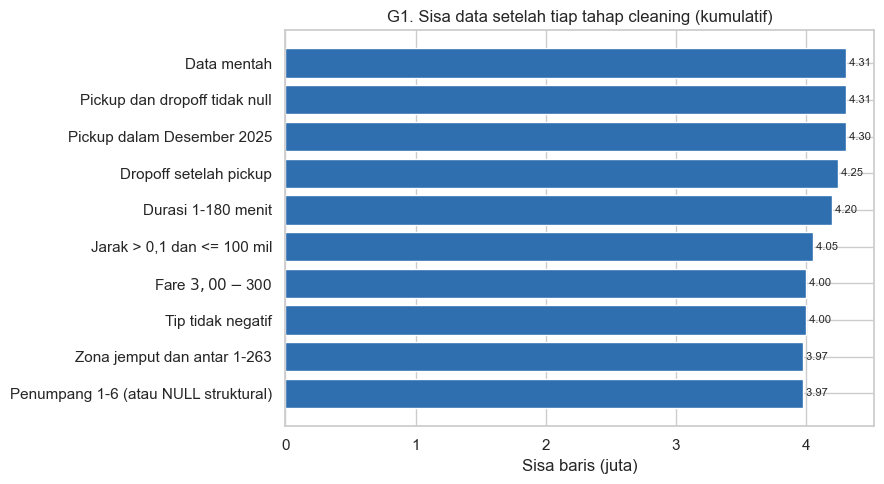

Sumber: agregasi Spark satu pass atas df_raw (bagian 5.2).


In [35]:
sns.set_theme(style="whitegrid")
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# G1: Waterfall cleaning (sumber: tabel waterfall, bagian 5.2)
fig, ax = plt.subplots(figsize=(9, 5))
wf = waterfall.iloc[::-1]
ax.barh(wf["tahap"], wf["sisa_baris"] / 1e6, color="#2f6fb0")
ax.set_xlabel("Sisa baris (juta)"); ax.set_title("G1. Sisa data setelah tiap tahap cleaning (kumulatif)")
for y, v in enumerate(wf["sisa_baris"] / 1e6):
    ax.text(v, y, f" {v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()
print("Sumber: agregasi Spark satu pass atas df_raw (bagian 5.2).")

**Interpretasi G1.** Dari 4.305.006 baris mentah tersisa 3.973.404 (92,30%). Pengurangan terbesar terjadi pada aturan jarak (148.823 baris) dan pada urutan waktu (58.021 baris, hampir seluruhnya Vendor 7 yang waktu dropoff-nya sama dengan pickup), disusul durasi (49.273) dan fare (47.157). Tahap lain membuang sangat sedikit. Karena aturan diterapkan berurutan, jumlah yang dibuang per tahap bergantung pada urutannya; audit individual di bagian 5.2 menunjukkan pelanggaran tiap aturan tanpa pengaruh urutan.

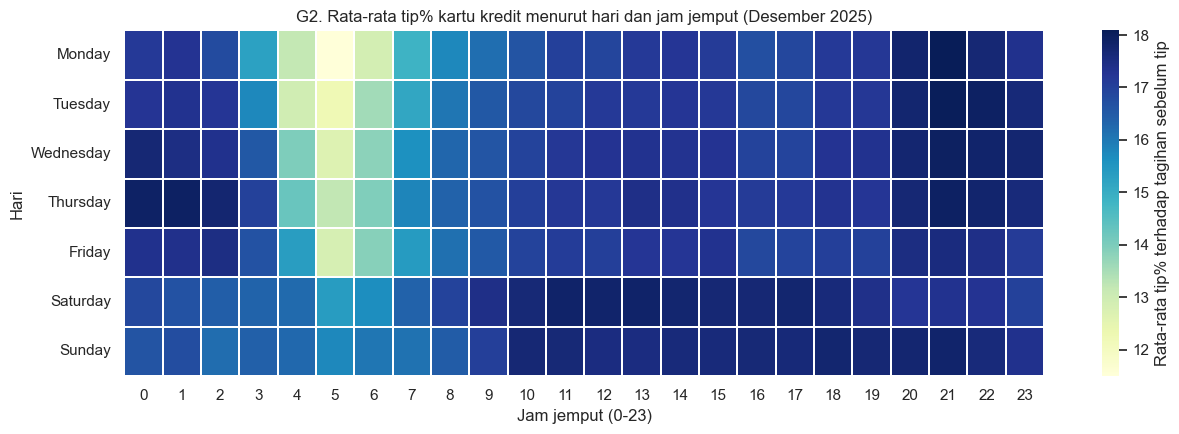

Sumber: tip_pdf (Spark groupBy hari-jam atas payment_type = 1, tip_pct_total di-cap 100%). Sel kosong = slot dengan < 500 trip.


In [36]:
# G2: heatmap rata-rata tip% (kartu kredit) menurut hari dan jam; sumber: tip_pdf (agregasi Q1, minimal 500 trip per slot)
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = tip_pdf.pivot(index="day_of_week", columns="pickup_hour", values="mean_tip_pct").reindex(DAYS)
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(pivot, cmap="YlGnBu", linewidths=0.3, ax=ax, cbar_kws={"label": "Rata-rata tip% terhadap tagihan sebelum tip"})
ax.set_title("G2. Rata-rata tip% kartu kredit menurut hari dan jam jemput (Desember 2025)")
ax.set_xlabel("Jam jemput (0-23)"); ax.set_ylabel("Hari")
plt.tight_layout(); plt.show()
print("Sumber: tip_pdf (Spark groupBy hari-jam atas payment_type = 1, tip_pct_total di-cap 100%). Sel kosong = slot dengan < 500 trip.")

**Interpretasi G2.** Warna paling pekat berada pada Senin-Kamis pukul 21:00-22:59 (puncak: Senin 21:00 sebesar 18,09%), sedangkan seluruh sebaran berada pada kisaran sempit di sekitar 17%. Kontras antar slot kecil, sejalan dengan hasil Q1 bahwa lima slot teratas tidak dapat dibedakan secara statistik. Hal ini mendukung kesimpulan bahwa waktu penjemputan hanya sedikit memengaruhi persentase tip kartu kredit.

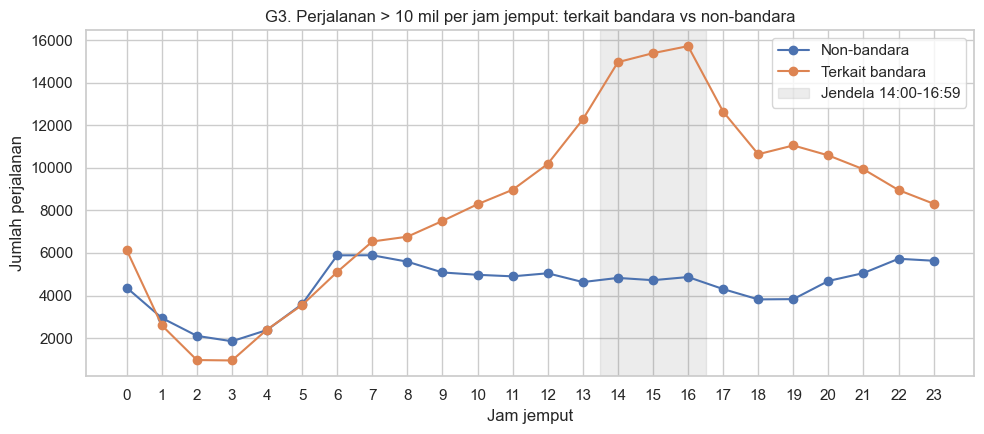

Sumber: Spark groupBy(pickup_hour, jenis) atas data bersih; bandara = zona 1, 132, 138 pada asal atau tujuan.


In [37]:
# G3: perjalanan jauh (> 10 mil) per jam, terkait bandara vs non-bandara; sumber: Spark groupBy atas df bersih
AIRPORT_IDS = [1, 132, 138]   # Newark, JFK, LaGuardia
is_air = F.col("PULocationID").isin(AIRPORT_IDS) | F.col("DOLocationID").isin(AIRPORT_IDS)
air_pdf = (df.filter(F.col("trip_distance") > 10)
             .withColumn("jenis", F.when(is_air, "Terkait bandara").otherwise("Non-bandara"))
             .groupBy("pickup_hour", "jenis").count().toPandas())
air_pv = air_pdf.pivot(index="pickup_hour", columns="jenis", values="count").sort_index()
fig, ax = plt.subplots(figsize=(10, 4.5))
air_pv.plot(ax=ax, marker="o")
ax.axvspan(13.5, 16.5, color="grey", alpha=0.15, label="Jendela 14:00-16:59")
ax.set_title("G3. Perjalanan > 10 mil per jam jemput: terkait bandara vs non-bandara")
ax.set_xlabel("Jam jemput"); ax.set_ylabel("Jumlah perjalanan"); ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout(); plt.show()
print("Sumber: Spark groupBy(pickup_hour, jenis) atas data bersih; bandara = zona 1, 132, 138 pada asal atau tujuan.")

**Interpretasi G3.** Perjalanan jauh terkait bandara memuncak pada 14:00-16:59 (14.964; 15.386; 15.717 per jam), sedangkan perjalanan jauh non-bandara hampir datar pada siang-sore (4.303-5.045 per jam pada 12:00-17:59) dan justru puncaknya pagi hari (5.891 pada 07:00). Jadi puncak sore perjalanan jauh adalah efek rute bandara. Pita abu-abu menandai jendela analisis; batasnya pilihan analis karena kurva bandara landai di sekitarnya.

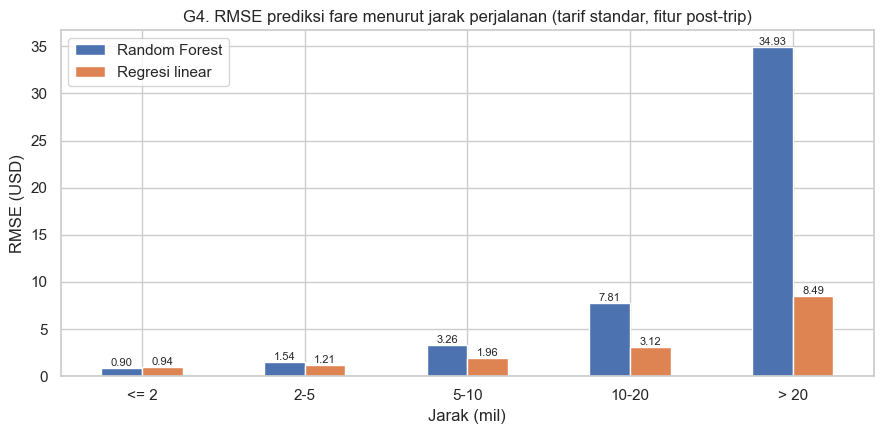

Sumber: model Random Forest dan regresi linear dari bagian 7, diuji pada test set RatecodeID = 1 (seed 42).


In [38]:
# G4: RMSE Random Forest vs regresi linear menurut kelompok jarak (tarif standar, post-trip); sumber: prediksi test standar
rf_m = models[("hanya RatecodeID=1", "Random Forest", "post")]
lr_m = models[("hanya RatecodeID=1", "Regresi linear", "post")]
pp = rf_m.transform(assemble(tests["test standar (RatecodeID=1)"], POST_COLS)).withColumnRenamed("prediction", "pred_rf")
pp = lr_m.transform(pp).withColumnRenamed("prediction", "pred_lr")
rmse_pdf = (pp.withColumn("jarak", F.when(F.col("trip_distance") <= 2, "<= 2")
                                    .when(F.col("trip_distance") <= 5, "2-5")
                                    .when(F.col("trip_distance") <= 10, "5-10")
                                    .when(F.col("trip_distance") <= 20, "10-20").otherwise("> 20"))
              .groupBy("jarak")
              .agg(F.count("*").alias("trips"),
                   F.sqrt(F.avg((F.col("pred_rf") - F.col("fare_amount")) ** 2)).alias("Random Forest"),
                   F.sqrt(F.avg((F.col("pred_lr") - F.col("fare_amount")) ** 2)).alias("Regresi linear"))
              .toPandas().set_index("jarak").reindex(["<= 2", "2-5", "5-10", "10-20", "> 20"]))
ax = rmse_pdf[["Random Forest", "Regresi linear"]].plot(kind="bar", figsize=(9, 4.5), rot=0)
ax.set_title("G4. RMSE prediksi fare menurut jarak perjalanan (tarif standar, fitur post-trip)")
ax.set_xlabel("Jarak (mil)"); ax.set_ylabel("RMSE (USD)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.show()
print("Sumber: model Random Forest dan regresi linear dari bagian 7, diuji pada test set RatecodeID = 1 (seed 42).")

**Interpretasi G4.** Pada jarak <= 2 mil (62,9% data uji) kedua model setara (RMSE $0,93 vs $0,92). Selisih membesar seiring jarak: $7,75 vs $3,15 pada 10-20 mil dan $34,76 vs $7,71 pada > 20 mil, kelompok yang hanya 0,3% data uji. Karena itu RMSE total Random Forest ($2,72) didorong oleh perjalanan jauh yang jarang, dan regresi linear lebih cocok untuk tarif yang naik hampir linear terhadap jarak.

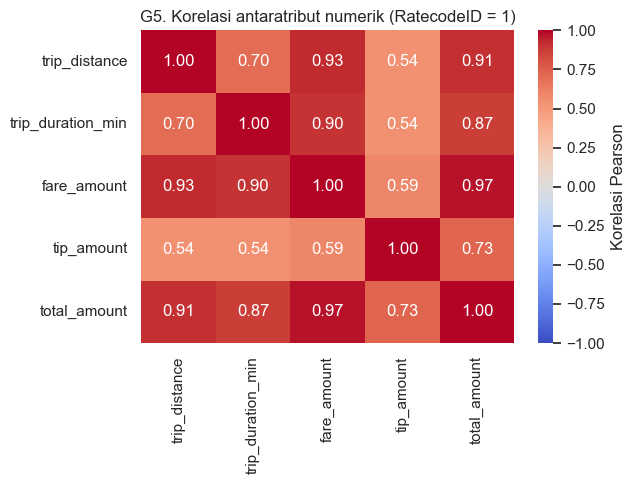

Sumber: Correlation.corr atas df_std (Spark MLlib), seluruh baris tarif standar.


In [39]:
# G5: korelasi Pearson antaratribut numerik utama (tarif standar); sumber: corr_pdf (MLlib Correlation, bagian 7)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr_pdf, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Korelasi Pearson"})
ax.set_title("G5. Korelasi antaratribut numerik (RatecodeID = 1)")
plt.tight_layout(); plt.show()
print("Sumber: Correlation.corr atas df_std (Spark MLlib), seluruh baris tarif standar.")

**Interpretasi G5.** `fare_amount` berkorelasi tinggi dengan jarak (0,93) dan durasi (0,90), sedangkan jarak dan durasi sendiri berkorelasi 0,70, artinya keduanya membawa informasi yang tumpang tindih; ini alasan drop-column dipakai untuk importance. `tip_amount` berkorelasi lebih rendah dengan fare (0,59) karena tip tunai tercatat nol dan tip bersifat diskresioner. Korelasi Pearson hanya mengukur hubungan linear dan tidak menunjukkan sebab-akibat.

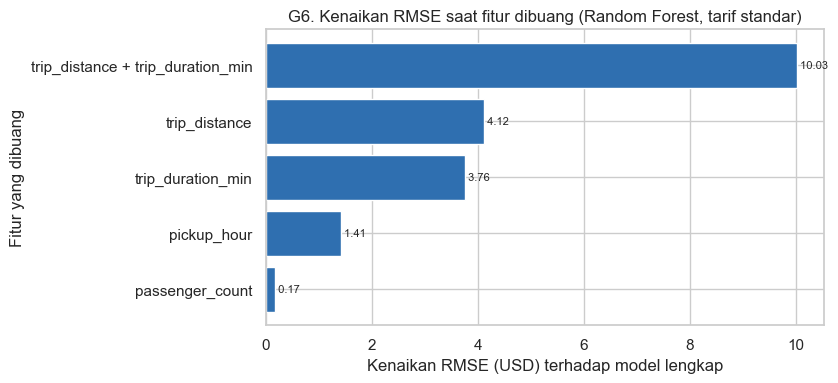

Sumber: imp_pdf; RMSE model lengkap 2.553 (RF 20 pohon, 30% data latih, satu seed).


In [40]:
# G6: drop-column importance (kenaikan RMSE saat fitur dibuang); sumber: imp_pdf (bagian 7)
imp_plot = imp_pdf.sort_values("kenaikan_RMSE")
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(imp_plot["fitur_dibuang"], imp_plot["kenaikan_RMSE"], color="#2f6fb0")
ax.set_title("G6. Kenaikan RMSE saat fitur dibuang (Random Forest, tarif standar)")
ax.set_xlabel("Kenaikan RMSE (USD) terhadap model lengkap"); ax.set_ylabel("Fitur yang dibuang")
for y, v in enumerate(imp_plot["kenaikan_RMSE"]):
    ax.text(v, y, f" {v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()
print(f"Sumber: imp_pdf; RMSE model lengkap {base_rmse:.3f} (RF 20 pohon, {IMP_FRACTION:.0%} data latih, satu seed).")

**Interpretasi G6.** Membuang jarak dan durasi sekaligus menaikkan RMSE $10,02, hampir kembali ke tingkat baseline rata-rata. Membuang salah satunya menaikkan $4,12 (jarak) atau $3,67 (durasi), sedangkan jumlah keduanya ($7,79) lebih kecil daripada saat dibuang bersamaan sehingga informasinya saling menggantikan. Jam jemput menambah $1,45 dan jumlah penumpang hanya $0,21, selisih yang belum dapat dibedakan dari variasi acak karena memakai satu seed.

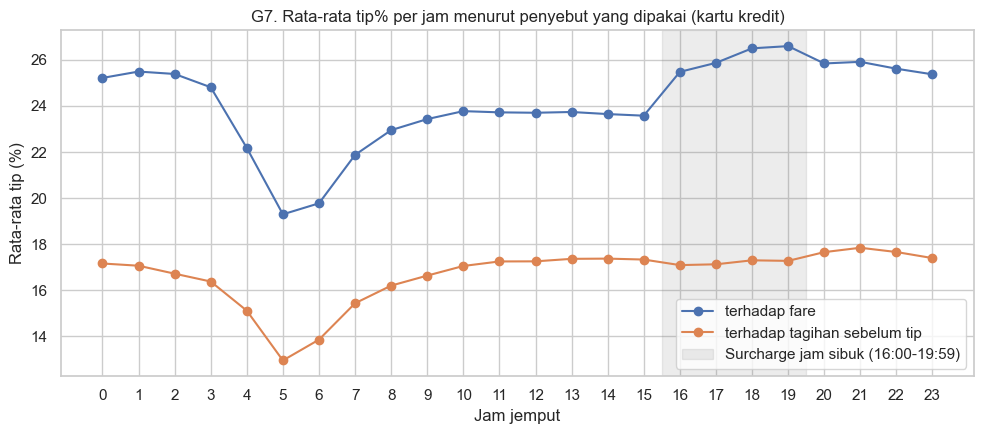

Sumber: Spark groupBy(pickup_hour) atas payment_type = 1; kedua ukuran di-cap 100%.


In [41]:
# G7: tip% kartu kredit per jam dengan dua penyebut (fare vs tagihan sebelum tip); sumber: agregasi Spark atas payment_type = 1
hr_pdf = (df.filter("payment_type = 1").groupBy("pickup_hour")
            .agg(F.avg("tip_pct").alias("terhadap fare"), F.avg("tip_pct_total").alias("terhadap tagihan sebelum tip"))
            .orderBy("pickup_hour").toPandas().set_index("pickup_hour"))
fig, ax = plt.subplots(figsize=(10, 4.5))
hr_pdf.plot(ax=ax, marker="o")
ax.axvspan(15.5, 19.5, color="grey", alpha=0.15, label="Surcharge jam sibuk (16:00-19:59)")
ax.set_title("G7. Rata-rata tip% per jam menurut penyebut yang dipakai (kartu kredit)")
ax.set_xlabel("Jam jemput"); ax.set_ylabel("Rata-rata tip (%)"); ax.set_xticks(range(0, 24)); ax.legend()
plt.tight_layout(); plt.show()
print("Sumber: Spark groupBy(pickup_hour) atas payment_type = 1; kedua ukuran di-cap 100%.")

**Interpretasi G7.** Terhadap fare, tip% naik dari sekitar 23,6% (14:00-15:59) menjadi 25,5-26,6% pada 16:00-19:59, bertepatan dengan surcharge jam sibuk, sedangkan terhadap tagihan sebelum tip kurvanya datar di sekitar 17,1-17,4% pada jam yang sama. Lonjakan terhadap fare karenanya sebagian besar berasal dari penyebut yang membesar, bukan dari tip yang lebih besar. Penurunan nyata hanya pada 04:00-07:00 (terendah 12,95% pukul 05:00 terhadap tagihan), yang sebabnya belum dapat dijelaskan dari data ini.

Task was destroyed but it is pending!
task: <Task pending name='Task-174' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\rifky\AppData\Roaming\Python\Python313\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-175' coro=<Kernel.shell_main() running at C:\Users\rifky\AppData\Roaming\Python\Python313\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\rifky\AppData\Roaming\Python\Python313\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\rifky\AppData\Roaming\Python\Python313\site-packages\pandas\core\indexes\base.py:5664: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  @final
Task was destroyed but it is pending!
task: <Task pending name='Task-175' coro=<Kernel.shell_main() running at C:\Users\rifky\AppData\Roaming\Python\Python313\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]>


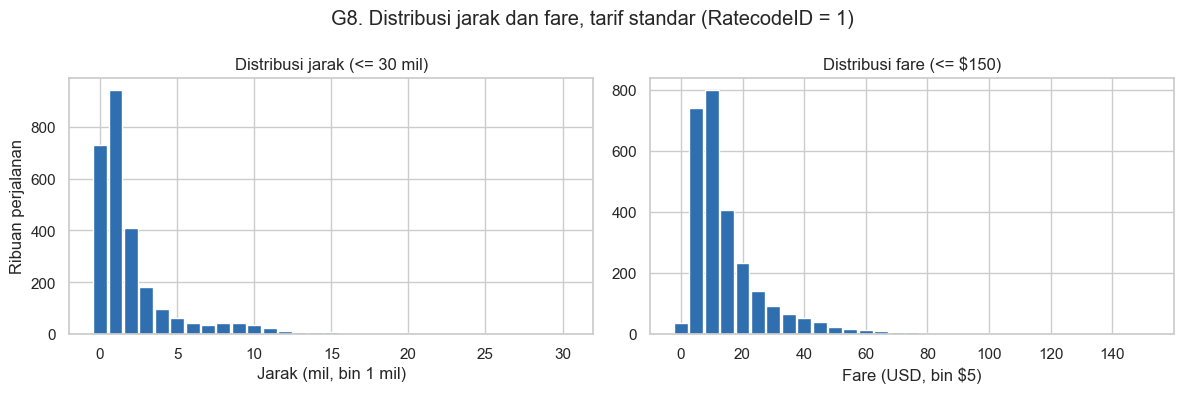

Sumber: Spark groupBy atas bin jarak dan fare pada df_std; nilai di atas batas tampilan tidak digambar.


In [42]:
# G8: distribusi jarak dan fare (tarif standar); binning di Spark, pandas hanya untuk hasil agregat
dist_pdf = (df_std.filter(F.col("trip_distance") <= 30)
              .withColumn("bin", F.floor(F.col("trip_distance")))
              .groupBy("bin").count().orderBy("bin").toPandas())
fare_pdf = (df_std.filter(F.col("fare_amount") <= 150)
              .withColumn("bin", (F.floor(F.col("fare_amount") / 5) * 5).cast("int"))
              .groupBy("bin").count().orderBy("bin").toPandas())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(dist_pdf["bin"], dist_pdf["count"] / 1e3, width=0.9, color="#2f6fb0")
axes[0].set_title("Distribusi jarak (<= 30 mil)"); axes[0].set_xlabel("Jarak (mil, bin 1 mil)"); axes[0].set_ylabel("Ribuan perjalanan")
axes[1].bar(fare_pdf["bin"], fare_pdf["count"] / 1e3, width=4.5, color="#2f6fb0")
axes[1].set_title("Distribusi fare (<= $150)"); axes[1].set_xlabel("Fare (USD, bin $5)")
fig.suptitle("G8. Distribusi jarak dan fare, tarif standar (RatecodeID = 1)")
plt.tight_layout(); plt.show()
print("Sumber: Spark groupBy atas bin jarak dan fare pada df_std; nilai di atas batas tampilan tidak digambar.")

**Interpretasi G8.** Jarak dan fare tarif standar sama-sama condong ke kanan dengan ekor panjang. Sebagian besar perjalanan pendek: kelompok terbesar berjarak 1-2 mil (sekitar 0,9 juta perjalanan), disusul 0-1 mil (sekitar 0,7 juta), lalu turun cepat sehingga perjalanan di atas 10 mil sangat sedikit. Fare terkonsentrasi pada $5-$15 (sekitar 0,7-0,8 juta perjalanan per kelompok $5) dan menipis di atas $40. Bentuk ini sejalan dengan median jarak 1,81 mil dan median fare $16,94 pada profiling, serta menjelaskan mengapa ambang cleaning (100 mil dan $300) berada jauh di dalam ekor dan hanya membuang nilai ekstrem. Grafik dipotong pada 30 mil dan $150, sehingga perjalanan di atas batas itu tidak terlihat, dan sebaran fare yang rapat di sisi kiri memperlihatkan efek biaya awal $3,00.

## 9. Temuan, keterbatasan, dan rekomendasi

### Jawaban ringkas atas pertanyaan

| Pertanyaan | Jawaban | Bukti |
|---|---|---|
| Q1 | Tip% kartu kredit tertinggi pada Senin-Kamis 21:00-22:59 (puncak 18,09% vs rata-rata 17,13%), tetapi lima slot teratas tidak dapat dibedakan secara statistik | Q1, G2, G7 |
| Q2 | Tujuan tersebar (terbesar JFK 11,91%), tetapi 76,17% perjalanan jauh 14:00-16:59 terkait bandara dan 41,99% berawal di JFK; puncak sore adalah efek rute bandara | Q2, G3 |
| Q3 | Pada tarif standar, regresi linear post-trip RMSE $1,34 (R² 0,989) mengalahkan Random Forest ($2,72) dan baseline ($12,62); tanpa durasi RMSE menjadi $4,69 | Bagian 7, G4-G6 |
| Q4 | Retensi 92,30%; NULL `passenger_count` (27,77%) bersifat struktural, seluruhnya `payment_type = 0` | Bagian 4.7-4.8, 5, G1 |
| Q5 | `cbd_congestion_fee` hanya 0 atau 0,75; `extra` Vendor 1 menyertakan komponen lain sehingga tidak dapat dibaca langsung | Q5 |

### Temuan utama

1. **Kualitas data dipengaruhi oleh sedikit sumber sistematis, bukan kesalahan acak.** Segmen `payment_type = 0` menyumbang seluruh NULL, dan Vendor 7 mencatat dropoff sama dengan pickup pada 57.416 baris (sekitar 99% pelanggaran urutan waktu). Setelah cleaning tersisa 3.973.404 baris (G1, tabel audit bagian 5.2).
2. **Tip tidak banyak berubah menurut waktu; beberapa lonjakan adalah artefak penyebut.** Rata-rata 17,13% terhadap tagihan sebelum tip, dengan keunggulan slot terbaik sekitar 1 poin persen (G2). Lonjakan terhadap fare pada jam sibuk hilang bila penyebutnya diganti (G7).
3. **Perjalanan jauh sore hari adalah perjalanan bandara.** Perjalanan non-bandara > 10 mil tidak memuncak di sore hari (G3).
4. **Tarif argo standar hampir sepenuhnya ditentukan oleh jarak dan durasi.** Model linear sederhana sudah cukup, dan kegagalan Random Forest terkonsentrasi pada perjalanan > 20 mil (G4, G6).
5. **Kolom biaya tidak seragam antarvendor.** Pada Vendor 1, `extra` tampak memuat komponen lain, sehingga `total_amount` lebih dapat diandalkan daripada penjumlahan kolom (Q5).

### Keterbatasan

- **Cakupan waktu.** Hanya Desember 2025 (musim libur); pola tip dan perjalanan bandara mungkin berbeda pada bulan lain.
- **Cakupan pembayaran.** Q1 hanya kartu kredit, sebab tip tunai tercatat nol dan segmen Flex Fare memiliki pencatatan berbeda. Rata-rata tip% mencampur proporsi trip tanpa tip dengan besar tip (proporsi tip nol belum dihitung).
- **Inferensi statistik.** Interval kepercayaan Q1 mengasumsikan trip independen dan tidak mengoreksi pemilihan slot tertinggi dari 168 slot.
- **Pemodelan.** Satu split dan satu seed, `ML_FRACTION = 0.5`, Random Forest tanpa tuning (30 pohon, kedalaman 8); selisih kecil antarmodel tidak dapat diuji signifikansinya. Model hanya berlaku untuk tarif standar.
- **Definisi dan klasifikasi.** Bandara didefinisikan lewat tiga ID zona dan ambang "jauh" 10 mil berdekatan dengan jarak bandara ke pusat kota; asal dan tujuan dianalisis terpisah, belum dipasangkan. Ambang cleaning adalah keputusan analis tanpa uji sensitivitas.
- **Belum terjelaskan.** Cara harga segmen `payment_type = 0` dibentuk, penurunan tip% pukul 04:00-07:00, dan sekitar 9,7% perjalanan Vendor 1 yang `extra`-nya belum cocok setelah koreksi.

### Rekomendasi

- **Pengemudi/pengelola armada:** perjalanan jauh sore hari terutama diperoleh di bandara, terutama JFK; keputusan menunggu di sana perlu data waktu tunggu dan antrean yang tidak ada di dataset ini. Jangan mengarahkan armada berdasarkan beda tip% antarslot teratas karena selisihnya kecil.
- **Perencana kebijakan (TLC/MTA):** `cbd_congestion_fee` tampak konsisten dengan toll $0,75, tetapi pencatatan `extra` oleh Vendor 1 dan dropoff Vendor 7 perlu diklarifikasi ke penyedia sebelum dipakai untuk evaluasi tarif.
- **Pengembang aplikasi tarif/ETA:** gunakan regresi linear untuk tarif argo standar (fitur pre-trip bila durasi belum diketahui) dan nyatakan batas pemakaian; jangan dipakai untuk tarif tetap JFK atau `payment_type = 0`.
- **Pekerjaan lanjutan:** tambahkan bulan lain, hitung proporsi tip nol, pasangkan asal-tujuan, dan uji sensitivitas ambang cleaning.

### Reproduksibilitas

Versi Python dan PySpark, konfigurasi Spark, dan seed (42) dicetak di bagian 3. Jalankan dengan *Restart kernel and Run All* karena nomor eksekusi sel pada versi sebelumnya melompat (urutan eksekusi tidak berurutan). Berkas yang dibutuhkan di folder kerja: `yellow_tripdata_2025-12.parquet` dan `taxi_zone_lookup.csv` (tautan di bagian 2). Pelatihan memakai `ML_FRACTION = 0.5`; menaikkannya ke 1,0 membutuhkan memori driver lebih besar dari 4 GB dan akan mengubah angka bagian 7.